In [1]:

import pandas as pd
import numpy as np
from pathlib import Path

from sklearn.model_selection import train_test_split, GroupShuffleSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Load the original datasets
DATA_DIR = Path("data")
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

df = pd.read_csv(DATA_DIR / "train.csv")
formulas = pd.read_csv(DATA_DIR / "unique_m.csv")

TARGET = "critical_temp"
FEATURES = [c for c in df.columns if c != TARGET]

print("Training data:", df.shape)
print("Formula data:", formulas.shape)
print("Features:", len(FEATURES))
print("Missing values:", int(df.isnull().sum().sum()))
print("Target:", TARGET)

assert len(df) == len(formulas), "Row counts do not match."
assert np.allclose(
    df[TARGET].to_numpy(),
    formulas[TARGET].to_numpy()
), "Target values do not align."

print("\nDataset loaded and target alignment verified.")


Training data: (21263, 82)
Formula data: (21263, 88)
Features: 81
Missing values: 0
Target: critical_temp

Dataset loaded and target alignment verified.


In [2]:

# Check whether each formula maps to one numerical feature vector
audit = pd.DataFrame({
    "material": formulas["material"],
    "feature_hash": pd.util.hash_pandas_object(
        df[FEATURES], index=False
    )
})

vectors_per_formula = audit.groupby("material")["feature_hash"].nunique()
formulas_per_vector = audit.groupby("feature_hash")["material"].nunique()

print(
    "Formulas associated with multiple feature vectors:",
    int((vectors_per_formula > 1).sum())
)

print(
    "Feature vectors associated with multiple formula strings:",
    int((formulas_per_vector > 1).sum())
)

print(
    "Unique formula strings:",
    formulas["material"].nunique()
)

print(
    "Unique numerical feature vectors:",
    df[FEATURES].drop_duplicates().shape[0]
)


Formulas associated with multiple feature vectors: 0
Feature vectors associated with multiple formula strings: 345
Unique formula strings: 15542
Unique numerical feature vectors: 15170


In [3]:

from sklearn.model_selection import GroupShuffleSplit

# Identify identical numerical feature vectors
groups = pd.util.hash_pandas_object(
    df[FEATURES], index=False
).to_numpy()

indices = np.arange(len(df))

# First split: 70% train, 30% temporary
split1 = GroupShuffleSplit(
    n_splits=1, test_size=0.30, random_state=42
)

train_idx, temp_idx = next(
    split1.split(indices, df[TARGET], groups=groups)
)

# Second split: divide the temporary set equally
split2 = GroupShuffleSplit(
    n_splits=1, test_size=0.50, random_state=42
)

val_rel, test_rel = next(
    split2.split(
        temp_idx,
        df.iloc[temp_idx][TARGET],
        groups=groups[temp_idx]
    )
)

val_idx = temp_idx[val_rel]
test_idx = temp_idx[test_rel]

# Create partitions
X_train = df.iloc[train_idx][FEATURES].copy()
y_train = df.iloc[train_idx][TARGET].copy()

X_val = df.iloc[val_idx][FEATURES].copy()
y_val = df.iloc[val_idx][TARGET].copy()

X_test = df.iloc[test_idx][FEATURES].copy()
y_test = df.iloc[test_idx][TARGET].copy()

print("Train:", X_train.shape, f"({len(train_idx)/len(df):.1%})")
print("Validation:", X_val.shape, f"({len(val_idx)/len(df):.1%})")
print("Test:", X_test.shape, f"({len(test_idx)/len(df):.1%})")

# Verify no feature-vector group crosses partitions
train_groups = set(groups[train_idx])
val_groups = set(groups[val_idx])
test_groups = set(groups[test_idx])

print("\nTrain-validation overlap:", len(train_groups & val_groups))
print("Train-test overlap:", len(train_groups & test_groups))
print("Validation-test overlap:", len(val_groups & test_groups))

assert not (train_groups & val_groups)
assert not (train_groups & test_groups)
assert not (val_groups & test_groups)

print("\nLeakage checks passed.")


Train: (14846, 81) (69.8%)
Validation: (3164, 81) (14.9%)
Test: (3253, 81) (15.3%)

Train-validation overlap: 0
Train-test overlap: 0
Validation-test overlap: 0

Leakage checks passed.


In [4]:

from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Baseline: predict the training-set mean for every sample
baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train, y_train)

val_pred = baseline.predict(X_val)

baseline_results = {
    "Model": "Dummy Regressor (Mean)",
    "MAE": mean_absolute_error(y_val, val_pred),
    "RMSE": np.sqrt(mean_squared_error(y_val, val_pred)),
    "R2": r2_score(y_val, val_pred)
}

display(pd.DataFrame([baseline_results]).round(4))


,Model,MAE,RMSE,R2
0,Dummy Regressor (Mean),28.861,33.6588,-0.0009


In [5]:

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

models = {
    "Linear Regression": make_pipeline(
        StandardScaler(),
        LinearRegression()
    ),
    "Ridge Regression": make_pipeline(
        StandardScaler(),
        Ridge(alpha=10.0)
    ),
    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ),
    "Extra Trees": ExtraTreesRegressor(
        n_estimators=200,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    )
}

results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_val)

    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_val, pred),
        "RMSE": np.sqrt(mean_squared_error(y_val, pred)),
        "R2": r2_score(y_val, pred)
    })

results_df = pd.DataFrame(results).sort_values("RMSE")
display(results_df.round(4))


,Model,MAE,RMSE,R2
3,Extra Trees,5.4953,9.4145,0.9217
2,Random Forest,5.9233,9.8533,0.9142
0,Linear Regression,13.7823,18.1578,0.7087
1,Ridge Regression,13.8413,18.2591,0.7055


In [6]:

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

generalization_results = []

for name in ["Extra Trees", "Random Forest"]:
    model = models[name]

    for split_name, X, y in [
        ("Train", X_train, y_train),
        ("Validation", X_val, y_val)
    ]:
        pred = model.predict(X)

        generalization_results.append({
            "Model": name,
            "Split": split_name,
            "MAE": mean_absolute_error(y, pred),
            "RMSE": np.sqrt(mean_squared_error(y, pred)),
            "R2": r2_score(y, pred)
        })

generalization_df = pd.DataFrame(generalization_results)
display(generalization_df.round(4))


,Model,Split,MAE,RMSE,R2
0,Extra Trees,Train,2.1769,4.6391,0.9818
1,Extra Trees,Validation,5.4953,9.4145,0.9217
2,Random Forest,Train,2.8804,5.4448,0.9749
3,Random Forest,Validation,5.9233,9.8533,0.9142


In [7]:

import numpy as np
import pandas as pd

from sklearn.model_selection import GroupShuffleSplit
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Group identical numerical feature vectors together.
groups = pd.util.hash_pandas_object(
    X, index=False
).to_numpy()

# 70% train, 15% validation, 15% test approximately.
split1 = GroupShuffleSplit(
    n_splits=1, test_size=0.30, random_state=42
)

train_idx, remaining_idx = next(
    split1.split(X, y, groups=groups)
)

X_train_g, X_remaining = X.iloc[train_idx], X.iloc[remaining_idx]
y_train_g, y_remaining = y.iloc[train_idx], y.iloc[remaining_idx]

groups_remaining = groups[remaining_idx]

split2 = GroupShuffleSplit(
    n_splits=1, test_size=0.50, random_state=42
)

val_rel, test_rel = next(
    split2.split(
        X_remaining, y_remaining, groups=groups_remaining
    )
)

X_val_g = X_remaining.iloc[val_rel]
y_val_g = y_remaining.iloc[val_rel]

X_test_g = X_remaining.iloc[test_rel]
y_test_g = y_remaining.iloc[test_rel]

# Confirm no feature-vector group crosses partitions.
assert not (
    set(groups[train_idx]) & set(groups[remaining_idx])
)
assert not (
    set(groups_remaining[val_rel]) &
    set(groups_remaining[test_rel])
)

# Fit a fresh model only on the grouped training split.
group_model = ExtraTreesRegressor(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)
group_model.fit(X_train_g, y_train_g)

# Evaluate validation performance.
val_pred = group_model.predict(X_val_g)

print("Grouped validation results")
print("MAE:", round(mean_absolute_error(y_val_g, val_pred), 4))
print("RMSE:", round(np.sqrt(mean_squared_error(y_val_g, val_pred)), 4))
print("R2:", round(r2_score(y_val_g, val_pred), 4))

print("\nSplit sizes:")
print("Train:", len(X_train_g))
print("Validation:", len(X_val_g))
print("Test:", len(X_test_g))


Grouped validation results
MAE: 8.4904
RMSE: 12.8403
R2: 0.8728

Split sizes:
Train: 2230
Validation: 477
Test: 457


In [8]:

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Evaluate the already-trained grouped model on the held-out test set.
test_pred = group_model.predict(X_test_g)

test_results = pd.DataFrame([{
    "Model": "Extra Trees",
    "MAE": mean_absolute_error(y_test_g, test_pred),
    "RMSE": np.sqrt(mean_squared_error(y_test_g, test_pred)),
    "R2": r2_score(y_test_g, test_pred)
}])

display(test_results.round(4))

# Compare actual and predicted temperatures.
comparison = pd.DataFrame({
    "Actual critical temperature (K)": np.asarray(y_test_g),
    "Predicted critical temperature (K)": test_pred
})

display(comparison.head(10).round(3))


,Model,MAE,RMSE,R2
0,Extra Trees,7.4891,11.9423,0.8652


,Actual critical temperature (K),Predicted critical temperature (K)
0,22.0,26.439
1,30.0,26.439
2,28.0,26.439
3,60.0,84.003
4,65.0,45.104
5,30.0,33.607
6,87.0,83.877
7,29.2,25.507
8,89.4,91.055
9,73.0,81.483


In [9]:

from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

grouped_models = {
    "Extra Trees": ExtraTreesRegressor(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    ),
    "Random Forest": RandomForestRegressor(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    )
}

comparison_results = []

for name, model in grouped_models.items():
    model.fit(X_train_g, y_train_g)

    val_pred = model.predict(X_val_g)
    test_pred = model.predict(X_test_g)

    comparison_results.append({
        "Model": name,
        "Validation MAE": mean_absolute_error(y_val_g, val_pred),
        "Validation RMSE": np.sqrt(mean_squared_error(y_val_g, val_pred)),
        "Validation R2": r2_score(y_val_g, val_pred),
        "Test MAE": mean_absolute_error(y_test_g, test_pred),
        "Test RMSE": np.sqrt(mean_squared_error(y_test_g, test_pred)),
        "Test R2": r2_score(y_test_g, test_pred)
    })

display(pd.DataFrame(comparison_results).round(4))


,Model,Validation MAE,Validation RMSE,Validation R2,Test MAE,Test RMSE,Test R2
0,Extra Trees,8.4904,12.8403,0.8728,7.4891,11.9423,0.8652
1,Random Forest,9.1462,13.4951,0.8595,7.9096,12.3987,0.8547


In [10]:

# Check how often each material formula appears.
formula_counts = formulas["material"].value_counts()

print("Total records:", len(formulas))
print("Unique material formulas:", formulas["material"].nunique())
print("Repeated formula records:", int((formula_counts > 1).sum()))
print("Maximum records for one formula:", int(formula_counts.max()))

print("\nMost repeated formulas:")
display(formula_counts.head(10).rename("record_count").to_frame())


Total records: 21263
Unique material formulas: 15542
Repeated formula records: 2261
Maximum records for one formula: 110

Most repeated formulas:


,record_count
material,
Y1Ba2Cu3O7,110
Bi2Sr2Ca1Cu2O8,80
La1.85Sr0.15Cu1O4,51
B2Mg1,46
Tl2Ba2Cu1O6,45
Y1Ba2Cu3O,44
Bi2Sr2Ca1Cu2O,44
Y1Ba2Cu4O8,40
Nd1.85Ce0.15Cu1O4,32


In [11]:

import numpy as np
import pandas as pd

from sklearn.model_selection import GroupShuffleSplit
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Use formula strings as groups.
groups = formulas["material"].astype(str).to_numpy()

# First split: 20% held out for final testing.
outer_split = GroupShuffleSplit(
    n_splits=1, test_size=0.20, random_state=42
)

train_val_idx, test_idx = next(
    outer_split.split(df[FEATURES], df[TARGET], groups=groups)
)

# Second split: validation from the remaining 80%.
inner_split = GroupShuffleSplit(
    n_splits=1, test_size=0.1875, random_state=43
)

train_rel, val_rel = next(
    inner_split.split(
        df.iloc[train_val_idx][FEATURES],
        df.iloc[train_val_idx][TARGET],
        groups=groups[train_val_idx]
    )
)

train_idx = train_val_idx[train_rel]
val_idx = train_val_idx[val_rel]

# Verify formula groups do not overlap.
train_groups = set(groups[train_idx])
val_groups = set(groups[val_idx])
test_groups = set(groups[test_idx])

assert train_groups.isdisjoint(val_groups)
assert train_groups.isdisjoint(test_groups)
assert val_groups.isdisjoint(test_groups)

print("Train rows:", len(train_idx))
print("Validation rows:", len(val_idx))
print("Test rows:", len(test_idx))
print("Formula overlap:", 0)

# Train a fresh model using training data only.
model_grouped = ExtraTreesRegressor(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

X_train_g = df.iloc[train_idx][FEATURES]
y_train_g = df.iloc[train_idx][TARGET]

X_val_g = df.iloc[val_idx][FEATURES]
y_val_g = df.iloc[val_idx][TARGET]

model_grouped.fit(X_train_g, y_train_g)
val_pred_g = model_grouped.predict(X_val_g)

print("\nFormula-grouped validation metrics")
print("MAE:", round(mean_absolute_error(y_val_g, val_pred_g), 4))
print("RMSE:", round(np.sqrt(mean_squared_error(y_val_g, val_pred_g)), 4))
print("R²:", round(r2_score(y_val_g, val_pred_g), 4))


Train rows: 13787
Validation rows: 3202
Test rows: 4274
Formula overlap: 0

Formula-grouped validation metrics
MAE: 5.2395
RMSE: 9.244
R²: 0.926


In [12]:

# Check for identical numerical feature vectors across splits.

def feature_hashes(indices):
    return set(
        pd.util.hash_pandas_object(
            df.iloc[indices][FEATURES],
            index=False
        ).to_numpy()
    )

train_hashes = feature_hashes(train_idx)
val_hashes = feature_hashes(val_idx)
test_hashes = feature_hashes(test_idx)

print("Train-validation feature overlap:",
      len(train_hashes & val_hashes))

print("Train-test feature overlap:",
      len(train_hashes & test_hashes))

print("Validation-test feature overlap:",
      len(val_hashes & test_hashes))


Train-validation feature overlap: 73
Train-test feature overlap: 85
Validation-test feature overlap: 20


In [13]:

import numpy as np
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit

# Group identical numerical feature vectors together.
feature_groups = pd.util.hash_pandas_object(
    df[FEATURES],
    index=False
).to_numpy()

# First split: 80% development data, 20% test data.
outer_split = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

dev_idx, test_idx_new = next(
    outer_split.split(df[FEATURES], df[TARGET],
                      groups=feature_groups)
)

# Second split: approximately 15% validation overall.
inner_split = GroupShuffleSplit(
    n_splits=1,
    test_size=0.1875,
    random_state=42
)

train_rel, val_rel = next(
    inner_split.split(
        df.iloc[dev_idx][FEATURES],
        df.iloc[dev_idx][TARGET],
        groups=feature_groups[dev_idx]
    )
)

train_idx_new = dev_idx[train_rel]
val_idx_new = dev_idx[val_rel]

# Verify feature-group separation.
train_groups = set(feature_groups[train_idx_new])
val_groups = set(feature_groups[val_idx_new])
test_groups = set(feature_groups[test_idx_new])

print("Train rows:", len(train_idx_new))
print("Validation rows:", len(val_idx_new))
print("Test rows:", len(test_idx_new))

print("Train-validation overlap:",
      len(train_groups & val_groups))
print("Train-test overlap:",
      len(train_groups & test_groups))
print("Validation-test overlap:",
      len(val_groups & test_groups))


Train rows: 13856
Validation rows: 3177
Test rows: 4230
Train-validation overlap: 0
Train-test overlap: 0
Validation-test overlap: 0


In [14]:

from sklearn.ensemble import ExtraTreesRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np
import pandas as pd

# Prepare the new splits.
X_train_new = df.iloc[train_idx_new][FEATURES]
y_train_new = df.iloc[train_idx_new][TARGET]

X_val_new = df.iloc[val_idx_new][FEATURES]
y_val_new = df.iloc[val_idx_new][TARGET]

X_test_new = df.iloc[test_idx_new][FEATURES]
y_test_new = df.iloc[test_idx_new][TARGET]

# Train using only the training split.
model_new = ExtraTreesRegressor(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

model_new.fit(X_train_new, y_train_new)

# Evaluate on validation data first.
val_pred_new = model_new.predict(X_val_new)

print("VALIDATION RESULTS")
print("MAE:", round(
    mean_absolute_error(y_val_new, val_pred_new), 4
))
print("RMSE:", round(
    np.sqrt(mean_squared_error(y_val_new, val_pred_new)), 4
))
print("R2:", round(
    r2_score(y_val_new, val_pred_new), 4
))


VALIDATION RESULTS
MAE: 5.0996
RMSE: 8.9623
R2: 0.9292


In [15]:

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np
import pandas as pd

def evaluate_split(name, X, y):
    pred = model_new.predict(X)

    return {
        "Split": name,
        "MAE": mean_absolute_error(y, pred),
        "RMSE": np.sqrt(mean_squared_error(y, pred)),
        "R2": r2_score(y, pred)
    }

overfit_check = pd.DataFrame([
    evaluate_split("Train", X_train_new, y_train_new),
    evaluate_split("Validation", X_val_new, y_val_new)
])

display(overfit_check.round(4))


,Split,MAE,RMSE,R2
0,Train,1.3871,4.2099,0.9850
1,Validation,5.0996,8.9623,0.9292


In [16]:

from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

models_to_compare = {
    "Extra Trees": ExtraTreesRegressor(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    ),
    "Random Forest": RandomForestRegressor(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    )
}

results = []

for name, model in models_to_compare.items():
    model.fit(X_train_new, y_train_new)

    for split_name, X, y in [
        ("Train", X_train_new, y_train_new),
        ("Validation", X_val_new, y_val_new)
    ]:
        pred = model.predict(X)

        results.append({
            "Model": name,
            "Split": split_name,
            "MAE": mean_absolute_error(y, pred),
            "RMSE": np.sqrt(mean_squared_error(y, pred)),
            "R2": r2_score(y, pred)
        })

display(pd.DataFrame(results).round(4))


,Model,Split,MAE,RMSE,R2
0,Extra Trees,Train,1.3871,4.2099,0.9850
1,Extra Trees,Validation,5.0996,8.9623,0.9292
2,Random Forest,Train,2.7061,5.1442,0.9777
3,Random Forest,Validation,5.4617,9.3820,0.9224


In [17]:

from sklearn.ensemble import ExtraTreesRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np
import pandas as pd

configs = [
    {"max_depth": None, "min_samples_leaf": 1, "max_features": 1.0},
    {"max_depth": 30, "min_samples_leaf": 2, "max_features": 1.0},
    {"max_depth": 20, "min_samples_leaf": 2, "max_features": 1.0},
    {"max_depth": 30, "min_samples_leaf": 3, "max_features": 0.8},
    {"max_depth": 20, "min_samples_leaf": 3, "max_features": 0.8},
]

tuning_results = []

for config in configs:
    model = ExtraTreesRegressor(
        n_estimators=300,
        random_state=42,
        n_jobs=-1,
        **config
    )

    model.fit(X_train_new, y_train_new)

    train_pred = model.predict(X_train_new)
    val_pred = model.predict(X_val_new)

    tuning_results.append({
        **config,
        "Train MAE": mean_absolute_error(
            y_train_new, train_pred
        ),
        "Validation MAE": mean_absolute_error(
            y_val_new, val_pred
        ),
        "Validation RMSE": np.sqrt(
            mean_squared_error(y_val_new, val_pred)
        ),
        "Validation R2": r2_score(y_val_new, val_pred)
    })

tuning_df = pd.DataFrame(tuning_results)
display(
    tuning_df.sort_values("Validation RMSE").round(4)
)


,max_depth,min_samples_leaf,max_features,Train MAE,Validation MAE,Validation RMSE,Validation R2
0,NaN,1,1.0,1.3871,5.0996,8.9623,0.9292
1,30.0,2,1.0,2.2384,5.1560,8.9881,0.9288
2,20.0,2,1.0,2.4202,5.2032,8.9949,0.9286
3,30.0,3,0.8,2.9461,5.2686,9.0504,0.9278
4,20.0,3,0.8,3.0693,5.3211,9.0911,0.9271


In [18]:

from sklearn.ensemble import ExtraTreesRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np
import pandas as pd

# Final model selected using validation results.
final_model = ExtraTreesRegressor(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

# Train only on the grouped training split.
final_model.fit(X_train_new, y_train_new)

# Evaluate once on the untouched grouped test split.
test_pred = final_model.predict(X_test_new)

test_results = pd.DataFrame([{
    "Model": "Extra Trees Regressor",
    "Test MAE (K)": mean_absolute_error(
        y_test_new, test_pred
    ),
    "Test RMSE (K)": np.sqrt(
        mean_squared_error(y_test_new, test_pred)
    ),
    "Test R2": r2_score(y_test_new, test_pred)
}])

display(test_results.round(4))

# Compare actual and predicted temperatures.
comparison = pd.DataFrame({
    "Actual Tc (K)": np.asarray(y_test_new),
    "Predicted Tc (K)": test_pred
})

comparison["Absolute Error (K)"] = np.abs(
    comparison["Actual Tc (K)"]
    - comparison["Predicted Tc (K)"]
)

display(comparison.head(10).round(3))


,Model,Test MAE (K),Test RMSE (K),Test R2
0,Extra Trees Regressor,5.7316,10.2918,0.9092


,Actual Tc (K),Predicted Tc (K),Absolute Error (K)
0,22.0,25.159,3.159
1,26.0,26.254,0.254
2,30.0,25.159,4.841
3,20.0,32.470,12.470
4,65.3,55.246,10.054
5,48.0,73.197,25.197
6,28.0,25.159,2.841
7,30.0,18.842,11.158
8,51.0,73.232,22.232
9,82.0,90.618,8.618


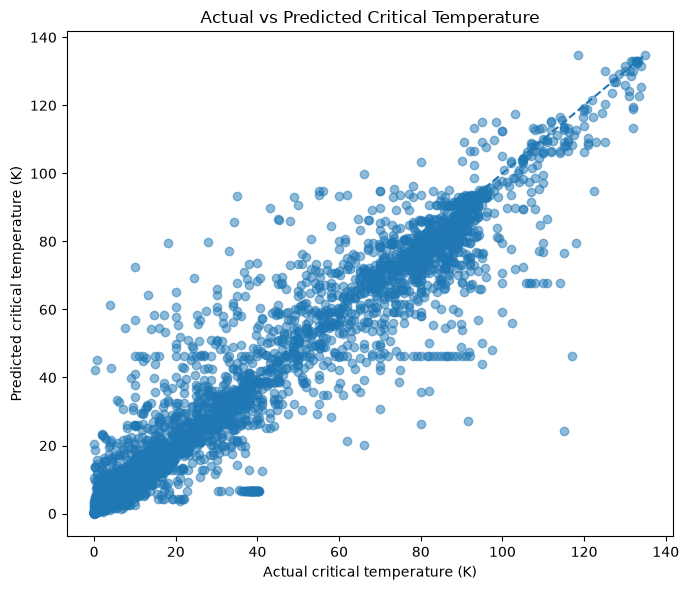

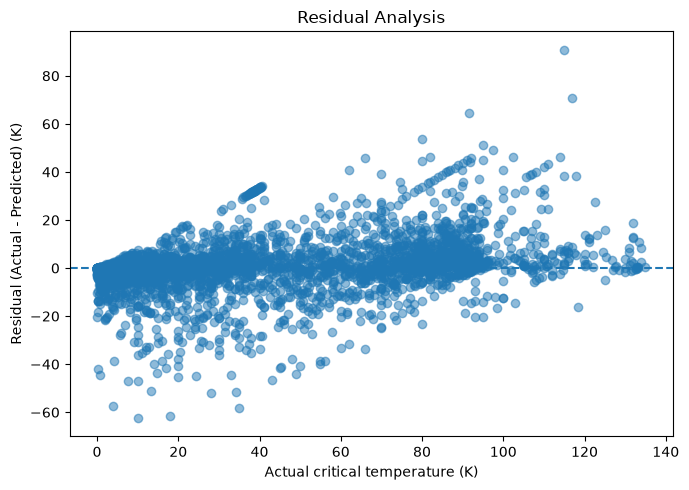

,Actual Tc (K),Predicted Tc (K),Absolute Error (K)
2840,115.00,24.150,90.850
454,117.00,46.210,70.790
1833,91.50,27.083,64.417
182,10.00,72.421,62.421
87,18.00,79.421,61.421
690,35.00,93.386,58.386
1612,4.00,61.315,57.315
2841,80.00,26.286,53.714
1460,28.00,79.797,51.797
156,34.30,85.712,51.412


In [19]:

import matplotlib.pyplot as plt
import numpy as np

actual = comparison["Actual Tc (K)"].to_numpy()
predicted = comparison["Predicted Tc (K)"].to_numpy()
residuals = actual - predicted

# Plot 1: Actual versus predicted.
plt.figure(figsize=(7, 6))
plt.scatter(actual, predicted, alpha=0.5)

lower = min(actual.min(), predicted.min())
upper = max(actual.max(), predicted.max())

plt.plot([lower, upper], [lower, upper], linestyle="--")
plt.xlabel("Actual critical temperature (K)")
plt.ylabel("Predicted critical temperature (K)")
plt.title("Actual vs Predicted Critical Temperature")
plt.tight_layout()
plt.show()

# Plot 2: Residuals versus actual temperature.
plt.figure(figsize=(7, 5))
plt.scatter(actual, residuals, alpha=0.5)
plt.axhline(0, linestyle="--")
plt.xlabel("Actual critical temperature (K)")
plt.ylabel("Residual (Actual - Predicted) (K)")
plt.title("Residual Analysis")
plt.tight_layout()
plt.show()

# Largest prediction errors.
error_analysis = comparison.copy()
error_analysis = error_analysis.sort_values(
    "Absolute Error (K)", ascending=False
)

display(error_analysis.head(20).round(3))


In [20]:

# Check whether identical numerical feature vectors
# have substantially different critical temperatures.

feature_cols = FEATURES  # Existing list of 81 feature columns

vector_audit = df.groupby(feature_cols)[TARGET].agg(
    record_count="size",
    unique_targets="nunique",
    min_target="min",
    max_target="max",
    mean_target="mean",
    std_target="std"
).reset_index()

vector_audit["target_range"] = (
    vector_audit["max_target"] - vector_audit["min_target"]
)

conflicts = vector_audit[
    (vector_audit["record_count"] > 1) &
    (vector_audit["target_range"] > 10)
].sort_values("target_range", ascending=False)

print("Repeated feature vectors with target range > 10 K:",
      len(conflicts))

display(conflicts.head(20))


Repeated feature vectors with target range > 10 K: 562


,number_of_elements,mean_atomic_mass,wtd_mean_atomic_mass,gmean_atomic_mass,wtd_gmean_atomic_mass,entropy_atomic_mass,wtd_entropy_atomic_mass,range_atomic_mass,wtd_range_atomic_mass,std_atomic_mass,...,wtd_range_Valence,std_Valence,wtd_std_Valence,record_count,unique_targets,min_target,max_target,mean_target,std_target,target_range
62,2,16.536470,11.360293,5.685033,3.193745,0.136394,0.224622,31.05706,10.016373,15.528530,...,1.333333,2.500000,2.357023e+00,2,2,60.0,185.0,122.500000,88.388348,125.0
7247,4,105.313925,76.633000,73.088376,42.605417,1.125848,1.158646,188.38390,31.383691,71.695924,...,0.909091,0.433013,3.856946e-01,45,45,10.0,117.0,58.888889,28.002258,107.0
5847,4,76.444563,51.245665,59.356672,34.935266,1.199541,1.291888,121.32760,14.288319,43.823354,...,0.846154,0.433013,2.664694e-01,110,110,30.3,130.0,85.469791,13.194568,99.7
10087,5,83.244760,97.046275,59.506081,73.675904,1.311510,1.198595,192.98100,50.245175,67.233835,...,1.000000,1.200000,1.299038e+00,44,44,14.6,97.0,78.050227,17.140194,82.4
7233,4,105.313925,69.175589,73.088376,39.908248,1.125848,1.223275,188.38390,23.456444,71.695924,...,0.888889,0.433013,3.142697e-01,2,2,15.0,95.0,55.000000,56.568542,80.0
9616,5,78.679650,77.906250,64.164718,66.074435,1.462708,1.336969,121.32760,27.141586,39.450875,...,0.714286,0.400000,3.499271e-01,5,5,11.0,90.0,54.800000,32.537670,79.0
5972,4,76.444563,54.182854,59.356672,37.284422,1.199541,1.278250,121.32760,15.479012,43.823354,...,0.750000,0.433013,2.763854e-01,5,5,13.7,91.1,31.940000,33.218715,77.4
10047,5,83.244760,59.224400,59.506081,36.126175,1.311510,1.372050,192.98100,25.192187,67.233835,...,0.933333,1.200000,1.019804e+00,83,83,25.0,99.0,77.924819,13.370836,74.0
7212,4,104.365600,75.348450,72.746865,44.633970,1.129463,1.199588,184.59060,26.388500,70.392496,...,0.750000,0.000000,0.000000e+00,28,28,26.0,98.0,76.217857,20.341511,72.0
5382,4,51.810850,41.831476,43.468565,32.273745,1.241927,1.237680,71.62060,13.195891,26.646429,...,0.868354,0.000000,2.220446e-16,3,3,40.0,110.0,83.333333,37.859389,70.0


In [22]:

print("DataFrame columns:")
print(df.columns.tolist())

print("\nFormula-related columns:")
print([
    col for col in df.columns
    if any(word in col.lower()
           for word in ["material", "formula", "composition"])
])

print("\nTarget column:", TARGET)


DataFrame columns:
['number_of_elements', 'mean_atomic_mass', 'wtd_mean_atomic_mass', 'gmean_atomic_mass', 'wtd_gmean_atomic_mass', 'entropy_atomic_mass', 'wtd_entropy_atomic_mass', 'range_atomic_mass', 'wtd_range_atomic_mass', 'std_atomic_mass', 'wtd_std_atomic_mass', 'mean_fie', 'wtd_mean_fie', 'gmean_fie', 'wtd_gmean_fie', 'entropy_fie', 'wtd_entropy_fie', 'range_fie', 'wtd_range_fie', 'std_fie', 'wtd_std_fie', 'mean_atomic_radius', 'wtd_mean_atomic_radius', 'gmean_atomic_radius', 'wtd_gmean_atomic_radius', 'entropy_atomic_radius', 'wtd_entropy_atomic_radius', 'range_atomic_radius', 'wtd_range_atomic_radius', 'std_atomic_radius', 'wtd_std_atomic_radius', 'mean_Density', 'wtd_mean_Density', 'gmean_Density', 'wtd_gmean_Density', 'entropy_Density', 'wtd_entropy_Density', 'range_Density', 'wtd_range_Density', 'std_Density', 'wtd_std_Density', 'mean_ElectronAffinity', 'wtd_mean_ElectronAffinity', 'gmean_ElectronAffinity', 'wtd_gmean_ElectronAffinity', 'entropy_ElectronAffinity', 'wtd_ent

In [23]:

# Inspect conflicting numerical feature vectors and target values.
# No material/formula column is required.

conflict_keys = conflicts[feature_cols].drop_duplicates().head(10)

conflict_records = df.merge(
    conflict_keys,
    on=feature_cols,
    how="inner"
)

display(
    conflict_records[
        feature_cols + [TARGET]
    ].sort_values(
        feature_cols
    ).head(50)
)


,number_of_elements,mean_atomic_mass,wtd_mean_atomic_mass,gmean_atomic_mass,wtd_gmean_atomic_mass,entropy_atomic_mass,wtd_entropy_atomic_mass,range_atomic_mass,wtd_range_atomic_mass,std_atomic_mass,...,wtd_mean_Valence,gmean_Valence,wtd_gmean_Valence,entropy_Valence,wtd_entropy_Valence,range_Valence,wtd_range_Valence,std_Valence,wtd_std_Valence,critical_temp
323,2,16.536470,11.360293,5.685033,3.193745,0.136394,0.224622,31.05706,10.016373,15.528530,...,2.666667,2.449490,1.817121,0.410116,0.562335,5,1.333333,2.500000,2.357023e+00,60.00
324,2,16.536470,11.360293,5.685033,3.193745,0.136394,0.224622,31.05706,10.016373,15.528530,...,2.666667,2.449490,1.817121,0.410116,0.562335,5,1.333333,2.500000,2.357023e+00,185.00
131,4,51.810850,41.831476,43.468565,32.273745,1.241927,1.237680,71.62060,13.195891,26.646429,...,2.000000,2.000000,2.000000,1.386294,1.182008,0,0.868354,0.000000,2.220446e-16,110.00
174,4,51.810850,41.831476,43.468565,32.273745,1.241927,1.237680,71.62060,13.195891,26.646429,...,2.000000,2.000000,2.000000,1.386294,1.182008,0,0.868354,0.000000,2.220446e-16,100.00
175,4,51.810850,41.831476,43.468565,32.273745,1.241927,1.237680,71.62060,13.195891,26.646429,...,2.000000,2.000000,2.000000,1.386294,1.182008,0,0.868354,0.000000,2.220446e-16,40.00
0,4,76.444563,51.245665,59.356672,34.935266,1.199541,1.291888,121.32760,14.288319,43.823354,...,2.076923,2.213364,2.063362,1.368922,1.201823,1,0.846154,0.433013,2.664694e-01,90.00
1,4,76.444563,51.245665,59.356672,34.935266,1.199541,1.291888,121.32760,14.288319,43.823354,...,2.076923,2.213364,2.063362,1.368922,1.201823,1,0.846154,0.433013,2.664694e-01,92.00
2,4,76.444563,51.245665,59.356672,34.935266,1.199541,1.291888,121.32760,14.288319,43.823354,...,2.076923,2.213364,2.063362,1.368922,1.201823,1,0.846154,0.433013,2.664694e-01,93.00
3,4,76.444563,51.245665,59.356672,34.935266,1.199541,1.291888,121.32760,14.288319,43.823354,...,2.076923,2.213364,2.063362,1.368922,1.201823,1,0.846154,0.433013,2.664694e-01,91.85
4,4,76.444563,51.245665,59.356672,34.935266,1.199541,1.291888,121.32760,14.288319,43.823354,...,2.076923,2.213364,2.063362,1.368922,1.201823,1,0.846154,0.433013,2.664694e-01,91.95


In [24]:

# Audit exact duplicate feature vectors.

audit = df.groupby(feature_cols, dropna=False)[TARGET].agg(
    record_count="size",
    unique_targets="nunique",
    min_target="min",
    max_target="max"
)

audit["target_range"] = (
    audit["max_target"] - audit["min_target"]
)

repeated = audit[audit["record_count"] > 1]
conflicting = repeated[repeated["unique_targets"] > 1]
large_conflicts = conflicting[conflicting["target_range"] > 10]

print("Repeated feature groups:", len(repeated))
print("Groups with different targets:", len(conflicting))
print("Groups with target range > 10 K:", len(large_conflicts))
print(
    "Records in large-conflict groups:",
    int(large_conflicts["record_count"].sum())
)

display(
    large_conflicts.sort_values(
        "target_range", ascending=False
    ).head(10)
)


Repeated feature groups: 2418
Groups with different targets: 2374
Groups with target range > 10 K: 562
Records in large-conflict groups: 3042


record_count  \
number_of_elements mean_atomic_mass wtd_mean_atomic_mass gmean_atomic_mass wtd_gmean_atomic_mass entropy_atomic_mass wtd_entropy_atomic_mass range_atomic_mass wtd_range_atomic_mass std_atomic_mass wtd_std_atomic_mass mean_fie wtd_mean_fie gmean_fie   wtd_gmean_fie entropy_fie wtd_entropy_fie range_fie wtd_range_fie std_fie    wtd_std_fie mean_atomic_radius wtd_mean_atomic_radius gmean_atomic_radius wtd_gmean_atomic_radius entropy_atomic_radius wtd_entropy_atomic_radius range_atomic_radius wtd_range_atomic_radius std_atomic_radius wtd_std_atomic_radius mean_Density wtd_mean_Density gmean_Density wtd_gmean_Density entropy_Density wtd_entropy_Density range_Density wtd_range_Density std_Density wtd_std_Density mean_ElectronAffinity wtd_mean_ElectronAffinity gmean_ElectronAffinity wtd_gmean_ElectronAffinity entropy_ElectronAffinity wtd_entropy_ElectronAffinity range_ElectronAffinity wtd_range_ElectronAffinity std_ElectronAffinity wtd_std_ElectronAffinity mean_FusionHeat wtd_mean_FusionHeat gmean_FusionHeat wtd_gmean_FusionHeat entropy_FusionHeat wtd_entropy_FusionHeat range_FusionHeat wtd_range_FusionHeat std_FusionHeat wtd_std_FusionHeat mean_ThermalConductivity wtd_mean_ThermalConductivity gmean_ThermalConductivity wtd_gmean_ThermalConductivity entropy_ThermalConductivity wtd_entropy_ThermalConductivity range_ThermalConductivity wtd_range_ThermalConductivity std_ThermalConductivity wtd_std_ThermalConductivity mean_Valence wtd_mean_Valence gmean_Valence wtd_gmean_Valence entropy_Valence wtd_entropy_Valence range_Valence wtd_range_Valence std_Valence wtd_std_Valence                 
2                  16.536470        11.360293            5.685033          3.193745              0.136394            0.224622                31.05706          10.016373             15.528530       14.640438           1155.150 1207.200000  1144.547378 1197.631481   0.683983    0.588986        312.3     541.200000    156.150000 147.219632  70.00              64.333333              67.904344           62.520676               0.663360              0.688294                  34                  6.333333                17.000000         16.027754             980.04495    653.393267       13.274185     2.511454          0.000504        0.000944            1959.9101     653.273400        979.955050  923.910481      137.9000              116.700000                122.357877             103.613790                 0.582659                 0.681688                     127.20                 17.633333                  63.600000            59.962655                1.1440          0.948667            0.982517         0.813651             0.555512           0.669691               1.172            0.204667             0.586000       0.552486           0.192750                 0.188667                     0.192360                  0.188323                      0.691126                    0.654668                        0.02450                   0.052000                      0.012250                0.011549                    3.50         2.666667         2.449490      1.817121          0.410116        0.562335            5             1.333333          2.500000    2.357023e+00                2   
4                  105.313925       76.633000            73.088376         42.605417             1.125848            1.158646                188.38390         31.383691             71.695924       75.219480           787.375  982.400000   733.513183  905.220526    1.312112    0.877227        810.6     648.509091    315.724764 367.154441  150.50             113.727273             128.740025          88.963038               1.258781              1.300361                  205                 32.818182               72.582711         79.353170             6080.35725   3608.052182      854.262665    67.474724         0.998141        0.952104            11848.5710    2153.766000       4613.600137 4695.920534     74.6375               95.200000                 48.348524 

In [25]:

# Inspect the largest target inconsistencies.

# 'audit' was created in your previous cell.
top_conflicts = (
    audit[audit["target_range"] > 10]
    .sort_values("target_range", ascending=False)
    .head(10)
    .reset_index()
)

for i, row in top_conflicts.iterrows():
    mask = df[feature_cols].eq(
        row[feature_cols].to_dict()
    ).all(axis=1)

    print(f"\nConflict {i + 1}")
    print("Number of records:", int(row["record_count"]))
    print("Minimum Tc:", row["min_target"], "K")
    print("Maximum Tc:", row["max_target"], "K")
    print("Target range:", row["target_range"], "K")
    print("Observed target values:")
    print(
        df.loc[mask, TARGET]
        .value_counts()
        .sort_index()
        .to_string()
    )



Conflict 1
Number of records: 2
Minimum Tc: 60.0 K
Maximum Tc: 185.0 K
Target range: 125.0 K
Observed target values:
critical_temp
60.0     1
185.0    1

Conflict 2
Number of records: 45
Minimum Tc: 10.0 K
Maximum Tc: 117.0 K
Target range: 107.0 K
Observed target values:
critical_temp
10.0     1
11.0     1
12.0     1
15.0     1
16.0     1
20.0     1
24.0     1
25.0     1
26.0     1
27.0     1
33.0     1
37.0     1
38.0     1
40.0     1
47.0     1
49.0     1
50.0     1
51.0     1
52.0     1
55.0     1
59.0     1
60.0     1
61.0     1
62.0     1
68.0     1
72.0     1
75.0     1
76.0     1
78.0     1
79.0     1
80.0     1
81.5     1
82.0     1
83.0     1
84.0     1
85.0     1
86.0     1
86.5     1
87.0     1
88.0     1
88.9     1
90.0     1
91.0     1
92.1     1
117.0    1

Conflict 3
Number of records: 110
Minimum Tc: 30.3 K
Maximum Tc: 130.0 K
Target range: 99.7 K
Observed target values:
critical_temp
30.300     1
39.000     1
44.700     1
50.000     1
52.000     1
53.000     1
57.000 

In [26]:
import pandas as pd
import numpy as np
from IPython.display import display

TARGET = "critical_temp"

# Use your existing DataFrames:
# df = numerical training dataset with 81 features + critical_temp
# formula_df = dataset containing material formulas

# Identify numerical feature columns
feature_cols = [c for c in df.columns if c != TARGET]

# Group identical feature vectors and summarize their targets
conflicts = (
    df.groupby(feature_cols, dropna=False)[TARGET]
    .agg(
        record_count="size",
        unique_targets="nunique",
        min_target="min",
        max_target="max",
        mean_target="mean",
        std_target="std"
    )
    .reset_index()
)

# Calculate the target range
conflicts["target_range"] = (
    conflicts["max_target"] - conflicts["min_target"]
)

# Keep groups with multiple target values and sort by largest conflict
conflicts = conflicts[
    conflicts["unique_targets"] > 1
].sort_values("target_range", ascending=False)

print("Total conflicting feature groups:", len(conflicts))
print("\nTop 10 largest critical-temperature conflicts:")

display(
    conflicts[
        ["record_count", "unique_targets", "min_target",
         "max_target", "mean_target", "target_range"]
    ].head(10).round(3)
)

Total conflicting feature groups: 2374

Top 10 largest critical-temperature conflicts:


,record_count,unique_targets,min_target,max_target,mean_target,target_range
62,2,2,60.0,185.0,122.500,125.0
7247,45,45,10.0,117.0,58.889,107.0
5847,110,110,30.3,130.0,85.470,99.7
10087,44,44,14.6,97.0,78.050,82.4
7233,2,2,15.0,95.0,55.000,80.0
9616,5,5,11.0,90.0,54.800,79.0
5972,5,5,13.7,91.1,31.940,77.4
10047,83,83,25.0,99.0,77.925,74.0
7212,28,28,26.0,98.0,76.218,72.0
5382,3,3,40.0,110.0,83.333,70.0


In [28]:
import pandas as pd

# Load the material formula dataset
formula_df = pd.read_csv("data/unique_m.csv")

print("Shape:", formula_df.shape)
print("\nColumns:")
print(formula_df.columns.tolist())

print("\nFirst 5 rows:")
display(formula_df.head())

Shape: (21263, 88)

Columns:
['H', 'He', 'Li', 'Be', 'B', 'C', 'N', 'O', 'F', 'Ne', 'Na', 'Mg', 'Al', 'Si', 'P', 'S', 'Cl', 'Ar', 'K', 'Ca', 'Sc', 'Ti', 'V', 'Cr', 'Mn', 'Fe', 'Co', 'Ni', 'Cu', 'Zn', 'Ga', 'Ge', 'As', 'Se', 'Br', 'Kr', 'Rb', 'Sr', 'Y', 'Zr', 'Nb', 'Mo', 'Tc', 'Ru', 'Rh', 'Pd', 'Ag', 'Cd', 'In', 'Sn', 'Sb', 'Te', 'I', 'Xe', 'Cs', 'Ba', 'La', 'Ce', 'Pr', 'Nd', 'Pm', 'Sm', 'Eu', 'Gd', 'Tb', 'Dy', 'Ho', 'Er', 'Tm', 'Yb', 'Lu', 'Hf', 'Ta', 'W', 'Re', 'Os', 'Ir', 'Pt', 'Au', 'Hg', 'Tl', 'Pb', 'Bi', 'Po', 'At', 'Rn', 'critical_temp', 'material']

First 5 rows:


,H,He,Li,Be,B,C,N,O,F,Ne,...,Au,Hg,Tl,Pb,Bi,Po,At,Rn,critical_temp,material
0,0.0,0,0.0,0.0,0.0,0.0,0.0,4.0,0.0,0,...,0.0,0.0,0.0,0.0,0.0,0,0,0,29.0,Ba0.2La1.8Cu1O4
1,0.0,0,0.0,0.0,0.0,0.0,0.0,4.0,0.0,0,...,0.0,0.0,0.0,0.0,0.0,0,0,0,26.0,Ba0.1La1.9Ag0.1Cu0.9O4
2,0.0,0,0.0,0.0,0.0,0.0,0.0,4.0,0.0,0,...,0.0,0.0,0.0,0.0,0.0,0,0,0,19.0,Ba0.1La1.9Cu1O4
3,0.0,0,0.0,0.0,0.0,0.0,0.0,4.0,0.0,0,...,0.0,0.0,0.0,0.0,0.0,0,0,0,22.0,Ba0.15La1.85Cu1O4
4,0.0,0,0.0,0.0,0.0,0.0,0.0,4.0,0.0,0,...,0.0,0.0,0.0,0.0,0.0,0,0,0,23.0,Ba0.3La1.7Cu1O4


In [29]:
print("Training dataset rows:", len(df))
print("Formula dataset rows:", len(formula_df))

print("\nFormula dataset columns:")
display(formula_df.head(10))

Training dataset rows: 21263
Formula dataset rows: 21263

Formula dataset columns:


,H,He,Li,Be,B,C,N,O,F,Ne,...,Au,Hg,Tl,Pb,Bi,Po,At,Rn,critical_temp,material
0,0.0,0,0.0,0.0,0.0,0.0,0.0,4.0,0.0,0,...,0.0,0.0,0.0,0.0,0.0,0,0,0,29.0,Ba0.2La1.8Cu1O4
1,0.0,0,0.0,0.0,0.0,0.0,0.0,4.0,0.0,0,...,0.0,0.0,0.0,0.0,0.0,0,0,0,26.0,Ba0.1La1.9Ag0.1Cu0.9O4
2,0.0,0,0.0,0.0,0.0,0.0,0.0,4.0,0.0,0,...,0.0,0.0,0.0,0.0,0.0,0,0,0,19.0,Ba0.1La1.9Cu1O4
3,0.0,0,0.0,0.0,0.0,0.0,0.0,4.0,0.0,0,...,0.0,0.0,0.0,0.0,0.0,0,0,0,22.0,Ba0.15La1.85Cu1O4
4,0.0,0,0.0,0.0,0.0,0.0,0.0,4.0,0.0,0,...,0.0,0.0,0.0,0.0,0.0,0,0,0,23.0,Ba0.3La1.7Cu1O4
5,0.0,0,0.0,0.0,0.0,0.0,0.0,4.0,0.0,0,...,0.0,0.0,0.0,0.0,0.0,0,0,0,23.0,Ba0.5La1.5Cu1O4
6,0.0,0,0.0,0.0,0.0,0.0,0.0,4.0,0.0,0,...,0.0,0.0,0.0,0.0,0.0,0,0,0,11.0,Ba1La1Cu1O4
7,0.0,0,0.0,0.0,0.0,0.0,0.0,4.0,0.0,0,...,0.0,0.0,0.0,0.0,0.0,0,0,0,33.0,Sr0.1La1.9Cu1O4
8,0.0,0,0.0,0.0,0.0,0.0,0.0,4.0,0.0,0,...,0.0,0.0,0.0,0.0,0.0,0,0,0,36.0,Sr0.15La1.85Cu1O4
9,0.0,0,0.0,0.0,0.0,0.0,0.0,4.0,0.0,0,...,0.0,0.0,0.0,0.0,0.0,0,0,0,31.0,Sr0.2La1.8Cu1O4


In [30]:
print("Same shape:", df.shape == formula_df.shape)

print("\nSame target values in same order:")
print(
    df[TARGET].reset_index(drop=True).equals(
        formula_df["critical_temp"].reset_index(drop=True)
    )
)

print("\nFirst 10 target comparisons:")
display(pd.DataFrame({
    "train_target": df[TARGET].head(10).to_numpy(),
    "formula_target": formula_df["critical_temp"].head(10).to_numpy(),
    "material": formula_df["material"].head(10).to_numpy()
}))

Same shape: False

Same target values in same order:
True

First 10 target comparisons:


,train_target,formula_target,material
0,29.0,29.0,Ba0.2La1.8Cu1O4
1,26.0,26.0,Ba0.1La1.9Ag0.1Cu0.9O4
2,19.0,19.0,Ba0.1La1.9Cu1O4
3,22.0,22.0,Ba0.15La1.85Cu1O4
4,23.0,23.0,Ba0.3La1.7Cu1O4
5,23.0,23.0,Ba0.5La1.5Cu1O4
6,11.0,11.0,Ba1La1Cu1O4
7,33.0,33.0,Sr0.1La1.9Cu1O4
8,36.0,36.0,Sr0.15La1.85Cu1O4
9,31.0,31.0,Sr0.2La1.8Cu1O4


In [31]:
formula_check = formula_df.copy()

print("Missing material values:",
      formula_check["material"].isna().sum())

print("Duplicate material formulas:",
      formula_check["material"].duplicated().sum())

formula_conflicts = (
    formula_check.groupby("material")["critical_temp"]
    .agg(
        record_count="size",
        unique_targets="nunique",
        min_target="min",
        max_target="max"
    )
    .reset_index()
)

formula_conflicts["target_range"] = (
    formula_conflicts["max_target"]
    - formula_conflicts["min_target"]
)

conflicts = formula_conflicts[
    formula_conflicts["unique_targets"] > 1
].sort_values("target_range", ascending=False)

print("Materials with different target values:", len(conflicts))
display(conflicts.head(20))

Missing material values: 0
Duplicate material formulas: 5721
Materials with different target values: 2261


,material,record_count,unique_targets,min_target,max_target,target_range
5121,H2S1,2,2,60.0,185.0,125.0
12904,Tl2Ba2Cu1O6,45,45,10.0,117.0,107.0
14964,Y1Ba2Cu3O7,110,110,30.3,130.0,99.7
2336,Bi2Sr2Ca1Cu2O,44,44,14.6,97.0,82.4
12705,Tl1Ba2Cu1O5,2,2,15.0,95.0,80.0
14860,Y1Ba2Cu3O6,5,5,13.7,91.1,77.4
2338,Bi2Sr2Ca1Cu2O8,80,80,25.0,99.0,74.0
13994,Y1Ba1.5Sr0.5Cu3O,4,4,11.0,84.0,73.0
5631,Hg1Ba2Cu1O4,28,28,26.0,98.0,72.0
2758,Ca0.285Sr0.665Cu1O2,3,3,40.0,110.0,70.0


In [32]:
# Inspect the original records for the five largest conflicts

top_materials = (
    conflicts.sort_values("target_range", ascending=False)
    .head(5)["material"]
    .tolist()
)

display(
    formula_df[
        formula_df["material"].isin(top_materials)
    ].sort_values(["material", "critical_temp"])
)

,H,He,Li,Be,B,C,N,O,F,Ne,...,Au,Hg,Tl,Pb,Bi,Po,At,Rn,critical_temp,material
6467,0.0,0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0,...,0.0,0.0,0.0,0.0,2.0,0,0,0,14.6,Bi2Sr2Ca1Cu2O
6468,0.0,0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0,...,0.0,0.0,0.0,0.0,2.0,0,0,0,27.8,Bi2Sr2Ca1Cu2O
8165,0.0,0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0,...,0.0,0.0,0.0,0.0,2.0,0,0,0,40.0,Bi2Sr2Ca1Cu2O
6469,0.0,0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0,...,0.0,0.0,0.0,0.0,2.0,0,0,0,50.0,Bi2Sr2Ca1Cu2O
8290,0.0,0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0,...,0.0,0.0,0.0,0.0,2.0,0,0,0,61.0,Bi2Sr2Ca1Cu2O
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
532,0.0,0,0.0,0.0,0.0,0.0,0.0,7.0,0.0,0,...,0.0,0.0,0.0,0.0,0.0,0,0,0,94.0,Y1Ba2Cu3O7
5069,0.0,0,0.0,0.0,0.0,0.0,0.0,7.0,0.0,0,...,0.0,0.0,0.0,0.0,0.0,0,0,0,94.3,Y1Ba2Cu3O7
953,0.0,0,0.0,0.0,0.0,0.0,0.0,7.0,0.0,0,...,0.0,0.0,0.0,0.0,0.0,0,0,0,95.0,Y1Ba2Cu3O7
2539,0.0,0,0.0,0.0,0.0,0.0,0.0,7.0,0.0,0,...,0.0,0.0,0.0,0.0,0.0,0,0,0,95.5,Y1Ba2Cu3O7


In [34]:

import pandas as pd
import numpy as np

# Identify numerical features available in formula_df
feature_cols = [
    col for col in formula_df.columns
    if col not in ["critical_temp", "material"]
    and pd.api.types.is_numeric_dtype(formula_df[col])
]

TARGET = "critical_temp"

audit_df = formula_df[
    feature_cols + [TARGET, "material"]
].copy()

# Group records by identical numerical feature vectors
feature_groups_audit = (
    audit_df.groupby(feature_cols, dropna=False)
    .agg(
        record_count=(TARGET, "size"),
        unique_targets=(TARGET, "nunique"),
        min_target=(TARGET, "min"),
        max_target=(TARGET, "max"),
        unique_materials=("material", "nunique")
    )
    .reset_index()
)

feature_groups_audit["target_range"] = (
    feature_groups_audit["max_target"]
    - feature_groups_audit["min_target"]
)

conflicting_features = (
    feature_groups_audit[
        feature_groups_audit["unique_targets"] > 1
    ]
    .sort_values("target_range", ascending=False)
)

print("Numerical features:", len(feature_cols))
print("Unique feature groups:", len(feature_groups_audit))
print("Groups with conflicting targets:", len(conflicting_features))

print(
    "Largest target range:",
    conflicting_features["target_range"].max()
    if not conflicting_features.empty else 0
)

display(conflicting_features.head(20))


Numerical features: 86
Unique feature groups: 15309
Groups with conflicting targets: 2353
Largest target range: 125.0


,H,He,Li,Be,B,C,N,O,F,Ne,...,Bi,Po,At,Rn,record_count,unique_targets,min_target,max_target,unique_materials,target_range
15258,2.0,0,0.0,0.0,0.0,0.0,0.0,0.00,0.0,0,...,0.0,0,0,0,2,2,60.0,185.0,1,125.0
8925,0.0,0,0.0,0.0,0.0,0.0,0.0,6.00,0.0,0,...,0.0,0,0,0,45,45,10.0,117.0,1,107.0
10935,0.0,0,0.0,0.0,0.0,0.0,0.0,7.00,0.0,0,...,0.0,0,0,0,110,110,30.3,130.0,1,99.7
6712,0.0,0,0.0,0.0,0.0,0.0,0.0,1.00,0.0,0,...,2.0,0,0,0,44,44,14.6,97.0,1,82.4
8792,0.0,0,0.0,0.0,0.0,0.0,0.0,5.00,0.0,0,...,0.0,0,0,0,2,2,15.0,95.0,1,80.0
6134,0.0,0,0.0,0.0,0.0,0.0,0.0,1.00,0.0,0,...,0.0,0,0,0,5,5,11.0,90.0,2,79.0
9029,0.0,0,0.0,0.0,0.0,0.0,0.0,6.00,0.0,0,...,0.0,0,0,0,5,5,13.7,91.1,1,77.4
12454,0.0,0,0.0,0.0,0.0,0.0,0.0,8.00,0.0,0,...,2.0,0,0,0,83,83,25.0,99.0,2,74.0
8025,0.0,0,0.0,0.0,0.0,0.0,0.0,4.00,0.0,0,...,0.0,0,0,0,28,28,26.0,98.0,1,72.0
7297,0.0,0,0.0,0.0,0.0,0.0,0.0,2.00,0.0,0,...,0.0,0,0,0,3,3,40.0,110.0,1,70.0


In [35]:

# Inspect the five feature groups with the largest target ranges

top_conflicts = conflicting_features.nlargest(
    5, "target_range"
)

conflict_records = formula_df.merge(
    top_conflicts[feature_cols],
    on=feature_cols,
    how="inner"
)

display(
    conflict_records.sort_values(
        ["material", TARGET]
    )[
        feature_cols + [TARGET, "material"]
    ].head(50)
)


,H,He,Li,Be,B,C,N,O,F,Ne,...,Au,Hg,Tl,Pb,Bi,Po,At,Rn,critical_temp,material
130,0.0,0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0,...,0.0,0.0,0.0,0.0,2.0,0,0,0,14.60,Bi2Sr2Ca1Cu2O
131,0.0,0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0,...,0.0,0.0,0.0,0.0,2.0,0,0,0,27.80,Bi2Sr2Ca1Cu2O
173,0.0,0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0,...,0.0,0.0,0.0,0.0,2.0,0,0,0,40.00,Bi2Sr2Ca1Cu2O
132,0.0,0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0,...,0.0,0.0,0.0,0.0,2.0,0,0,0,50.00,Bi2Sr2Ca1Cu2O
175,0.0,0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0,...,0.0,0.0,0.0,0.0,2.0,0,0,0,61.00,Bi2Sr2Ca1Cu2O
179,0.0,0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0,...,0.0,0.0,0.0,0.0,2.0,0,0,0,62.00,Bi2Sr2Ca1Cu2O
117,0.0,0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0,...,0.0,0.0,0.0,0.0,2.0,0,0,0,63.00,Bi2Sr2Ca1Cu2O
171,0.0,0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0,...,0.0,0.0,0.0,0.0,2.0,0,0,0,70.00,Bi2Sr2Ca1Cu2O
38,0.0,0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0,...,0.0,0.0,0.0,0.0,2.0,0,0,0,72.18,Bi2Sr2Ca1Cu2O
133,0.0,0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0,...,0.0,0.0,0.0,0.0,2.0,0,0,0,72.90,Bi2Sr2Ca1Cu2O


In [36]:

# Audit repeated feature vectors and their target values

feature_cols = [
    c for c in formula_df.columns
    if c not in [TARGET, "material"]
]

audit = (
    formula_df
    .groupby(feature_cols, dropna=False)
    .agg(
        record_count=(TARGET, "size"),
        unique_targets=(TARGET, "nunique"),
        min_target=(TARGET, "min"),
        max_target=(TARGET, "max"),
        unique_materials=("material", "nunique")
    )
    .reset_index()
)

audit["target_range"] = (
    audit["max_target"] - audit["min_target"]
)

print("Total records:", len(formula_df))
print("Unique feature vectors:", len(audit))
print(
    "Repeated vectors:",
    (audit["record_count"] > 1).sum()
)
print(
    "Vectors with conflicting targets:",
    (audit["unique_targets"] > 1).sum()
)

print("\nLargest target conflicts:")
display(
    audit[audit["unique_targets"] > 1]
    .sort_values("target_range", ascending=False)
    .head(10)[
        ["record_count", "unique_targets",
         "min_target", "max_target",
         "target_range", "unique_materials"]
    ]
)


Total records: 21263
Unique feature vectors: 15309
Repeated vectors: 2353
Vectors with conflicting targets: 2353

Largest target conflicts:


,record_count,unique_targets,min_target,max_target,target_range,unique_materials
15258,2,2,60.0,185.0,125.0,1
8925,45,45,10.0,117.0,107.0,1
10935,110,110,30.3,130.0,99.7,1
6712,44,44,14.6,97.0,82.4,1
8792,2,2,15.0,95.0,80.0,1
6134,5,5,11.0,90.0,79.0,2
9029,5,5,13.7,91.1,77.4,1
12454,83,83,25.0,99.0,74.0,2
8025,28,28,26.0,98.0,72.0,1
7297,3,3,40.0,110.0,70.0,1


In [37]:

# Inspect original records for the largest target conflicts

top_groups = (
    audit[audit["unique_targets"] > 1]
    .sort_values("target_range", ascending=False)
    .head(5)
)

# Match each conflicting feature vector to original records
conflict_records = formula_df.merge(
    top_groups[feature_cols],
    on=feature_cols,
    how="inner"
)

display(
    conflict_records
    .sort_values(["material", TARGET])
    [["material", TARGET] + feature_cols]
    .head(100)
)


,material,critical_temp,H,He,Li,Be,B,C,N,O,...,Ir,Pt,Au,Hg,Tl,Pb,Bi,Po,At,Rn
130,Bi2Sr2Ca1Cu2O,14.6,0.0,0,0.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,2.0,0,0,0
131,Bi2Sr2Ca1Cu2O,27.8,0.0,0,0.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,2.0,0,0,0
173,Bi2Sr2Ca1Cu2O,40.0,0.0,0,0.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,2.0,0,0,0
132,Bi2Sr2Ca1Cu2O,50.0,0.0,0,0.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,2.0,0,0,0
175,Bi2Sr2Ca1Cu2O,61.0,0.0,0,0.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,2.0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
182,Y1Ba2Cu3O7,44.7,0.0,0,0.0,0.0,0.0,0.0,0.0,7.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0
91,Y1Ba2Cu3O7,50.0,0.0,0,0.0,0.0,0.0,0.0,0.0,7.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0
156,Y1Ba2Cu3O7,52.0,0.0,0,0.0,0.0,0.0,0.0,0.0,7.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0
162,Y1Ba2Cu3O7,53.0,0.0,0,0.0,0.0,0.0,0.0,0.0,7.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0


In [38]:

# Analyze target variation for each material formula

material_audit = (
    formula_df.groupby("material")[TARGET]
    .agg(
        record_count="count",
        unique_temperatures="nunique",
        min_temp="min",
        max_temp="max",
        mean_temp="mean",
        std_temp="std"
    )
    .reset_index()
)

material_audit["temperature_range"] = (
    material_audit["max_temp"] -
    material_audit["min_temp"]
)

print("Unique material formulas:", len(material_audit))

print(
    "Formulas with multiple temperatures:",
    (material_audit["unique_temperatures"] > 1).sum()
)

print("\nFormulas with the largest temperature ranges:")

display(
    material_audit[
        material_audit["unique_temperatures"] > 1
    ]
    .sort_values("temperature_range", ascending=False)
    .head(20)
    .round(3)
)


Unique material formulas: 15542
Formulas with multiple temperatures: 2261

Formulas with the largest temperature ranges:


,material,record_count,unique_temperatures,min_temp,max_temp,mean_temp,std_temp,temperature_range
5121,H2S1,2,2,60.0,185.0,122.500,88.388,125.0
12904,Tl2Ba2Cu1O6,45,45,10.0,117.0,58.889,28.002,107.0
14964,Y1Ba2Cu3O7,110,110,30.3,130.0,85.470,13.195,99.7
2336,Bi2Sr2Ca1Cu2O,44,44,14.6,97.0,78.050,17.140,82.4
12705,Tl1Ba2Cu1O5,2,2,15.0,95.0,55.000,56.569,80.0
14860,Y1Ba2Cu3O6,5,5,13.7,91.1,31.940,33.219,77.4
2338,Bi2Sr2Ca1Cu2O8,80,80,25.0,99.0,77.628,13.515,74.0
13994,Y1Ba1.5Sr0.5Cu3O,4,4,11.0,84.0,46.000,29.922,73.0
5631,Hg1Ba2Cu1O4,28,28,26.0,98.0,76.218,20.342,72.0
2758,Ca0.285Sr0.665Cu1O2,3,3,40.0,110.0,83.333,37.859,70.0


In [39]:

# Summarize target conflicts at the material-formula level

conflict_summary = {
    "Total records": len(formula_df),
    "Unique formulas": formula_df["material"].nunique(),
    "Formulas with multiple temperatures": int(
        (material_audit["unique_temperatures"] > 1).sum()
    ),
    "Records belonging to conflicting formulas": int(
        formula_df["material"].isin(
            material_audit.loc[
                material_audit["unique_temperatures"] > 1,
                "material"
            ]
        ).sum()
    ),
    "Percentage of formulas with conflicts": round(
        100 * (material_audit["unique_temperatures"] > 1).mean(), 2
    )
}

display(pd.Series(conflict_summary, name="Value").to_frame())


,Value
Total records,21263.00
Unique formulas,15542.00
Formulas with multiple temperatures,2261.00
Records belonging to conflicting formulas,7982.00
Percentage of formulas with conflicts,14.55


In [40]:

# Check whether each formula maps to one numerical composition

formula_composition = (
    formula_df.groupby("material")[feature_cols]
    .nunique()
)

composition_summary = {
    "Formula count": len(formula_composition),
    "Formulas with varying numerical compositions": int(
        (formula_composition > 1).any(axis=1).sum()
    ),
    "Formulas with identical numerical compositions": int(
        (~(formula_composition > 1).any(axis=1)).sum()
    )
}

display(pd.Series(composition_summary, name="Value").to_frame())


,Value
Formula count,15542
Formulas with varying numerical compositions,0
Formulas with identical numerical compositions,15542


In [41]:

# Inspect the 10 formulas with the largest target ranges

top_conflict_materials = (
    material_audit
    .sort_values("temperature_range", ascending=False)
    .head(10)["material"]
    .tolist()
)

conflict_details = (
    formula_df[
        formula_df["material"].isin(top_conflict_materials)
    ]
    .groupby("material")
    .agg(
        record_count=("critical_temp", "size"),
        unique_temperatures=("critical_temp", "nunique"),
        min_temp=("critical_temp", "min"),
        max_temp=("critical_temp", "max"),
        mean_temp=("critical_temp", "mean"),
        std_temp=("critical_temp", "std")
    )
    .sort_values("max_temp", ascending=False)
)

display(conflict_details)


,record_count,unique_temperatures,min_temp,max_temp,mean_temp,std_temp
material,,,,,,
H2S1,2,2,60.0,185.0,122.500000,88.388348
Y1Ba2Cu3O7,110,110,30.3,130.0,85.469791,13.194568
Tl2Ba2Cu1O6,45,45,10.0,117.0,58.888889,28.002258
Ca0.285Sr0.665Cu1O2,3,3,40.0,110.0,83.333333,37.859389
Bi2Sr2Ca1Cu2O8,80,80,25.0,99.0,77.628250,13.515140
Hg1Ba2Cu1O4,28,28,26.0,98.0,76.217857,20.341511
Bi2Sr2Ca1Cu2O,44,44,14.6,97.0,78.050227,17.140194
Tl1Ba2Cu1O5,2,2,15.0,95.0,55.000000,56.568542
Y1Ba2Cu3O6,5,5,13.7,91.1,31.940000,33.218715


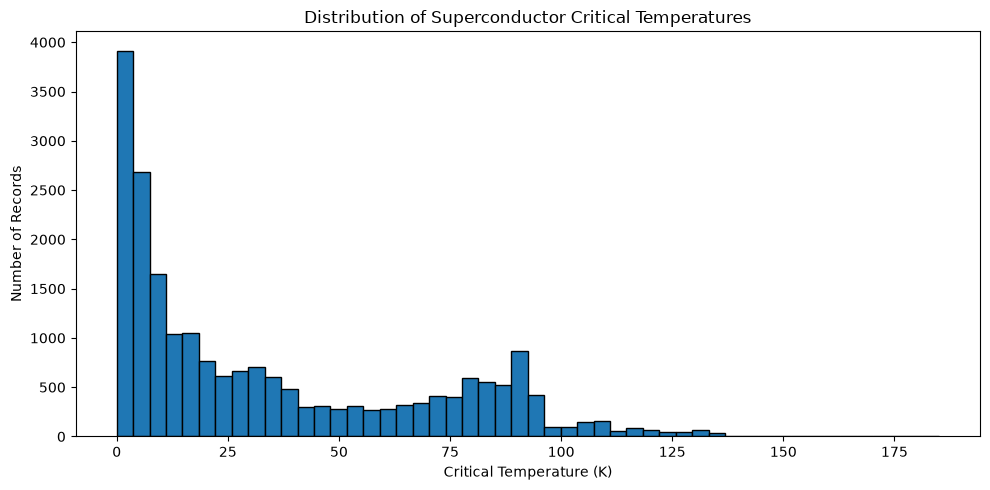

In [42]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.hist(formula_df["critical_temp"], bins=50, edgecolor="black")
plt.xlabel("Critical Temperature (K)")
plt.ylabel("Number of Records")
plt.title("Distribution of Superconductor Critical Temperatures")
plt.tight_layout()
plt.show()


In [43]:

# Inspect the original records for the five largest conflicts

top_conflict_materials = (
    material_audit
    .sort_values("temperature_range", ascending=False)
    .head(5)["material"]
    .tolist()
)

for material in top_conflict_materials:
    print(f"\nMaterial: {material}")

    records = (
        formula_df.loc[
            formula_df["material"] == material,
            ["material", "critical_temp"]
        ]
        .sort_values("critical_temp")
    )

    display(records)



Material: H2S1


,material,critical_temp
20572,H2S1,60.0
20573,H2S1,185.0



Material: Tl2Ba2Cu1O6


,material,critical_temp
6132,Tl2Ba2Cu1O6,10.0
7649,Tl2Ba2Cu1O6,11.0
4094,Tl2Ba2Cu1O6,12.0
2887,Tl2Ba2Cu1O6,15.0
2209,Tl2Ba2Cu1O6,16.0
2208,Tl2Ba2Cu1O6,20.0
7946,Tl2Ba2Cu1O6,24.0
7947,Tl2Ba2Cu1O6,25.0
10785,Tl2Ba2Cu1O6,26.0
10784,Tl2Ba2Cu1O6,27.0



Material: Y1Ba2Cu3O7


,material,critical_temp
10520,Y1Ba2Cu3O7,30.3
7934,Y1Ba2Cu3O7,39.0
9947,Y1Ba2Cu3O7,44.7
2754,Y1Ba2Cu3O7,50.0
7103,Y1Ba2Cu3O7,52.0
...,...,...
532,Y1Ba2Cu3O7,94.0
5069,Y1Ba2Cu3O7,94.3
953,Y1Ba2Cu3O7,95.0
2539,Y1Ba2Cu3O7,95.5



Material: Bi2Sr2Ca1Cu2O


,material,critical_temp
6467,Bi2Sr2Ca1Cu2O,14.60
6468,Bi2Sr2Ca1Cu2O,27.80
8165,Bi2Sr2Ca1Cu2O,40.00
6469,Bi2Sr2Ca1Cu2O,50.00
8290,Bi2Sr2Ca1Cu2O,61.00
8763,Bi2Sr2Ca1Cu2O,62.00
5107,Bi2Sr2Ca1Cu2O,63.00
7969,Bi2Sr2Ca1Cu2O,70.00
814,Bi2Sr2Ca1Cu2O,72.18
6470,Bi2Sr2Ca1Cu2O,72.90



Material: Tl1Ba2Cu1O5


,material,critical_temp
2032,Tl1Ba2Cu1O5,15.0
1842,Tl1Ba2Cu1O5,95.0


In [44]:

# Statistical summary of the target variable

display(
    formula_df["critical_temp"].describe().to_frame("Value")
)

print(
    "Skewness:",
    round(formula_df["critical_temp"].skew(), 3)
)

print(
    "Missing target values:",
    formula_df["critical_temp"].isna().sum()
)

print(
    "Infinite target values:",
    (~formula_df["critical_temp"].map(
        lambda x: pd.notna(x) and abs(x) != float("inf")
    )).sum()
)


,Value
count,21263.000000
mean,34.421219
std,34.254362
min,0.000210
25%,5.365000
50%,20.000000
75%,63.000000
max,185.000000


Skewness: 0.86
Missing target values: 0
Infinite target values: 0


In [46]:

print("Available columns:")
print(formula_df.columns.tolist())

print("\nFeature columns missing from formula_df:")
print([col for col in feature_cols if col not in formula_df.columns])


Available columns:
['H', 'He', 'Li', 'Be', 'B', 'C', 'N', 'O', 'F', 'Ne', 'Na', 'Mg', 'Al', 'Si', 'P', 'S', 'Cl', 'Ar', 'K', 'Ca', 'Sc', 'Ti', 'V', 'Cr', 'Mn', 'Fe', 'Co', 'Ni', 'Cu', 'Zn', 'Ga', 'Ge', 'As', 'Se', 'Br', 'Kr', 'Rb', 'Sr', 'Y', 'Zr', 'Nb', 'Mo', 'Tc', 'Ru', 'Rh', 'Pd', 'Ag', 'Cd', 'In', 'Sn', 'Sb', 'Te', 'I', 'Xe', 'Cs', 'Ba', 'La', 'Ce', 'Pr', 'Nd', 'Pm', 'Sm', 'Eu', 'Gd', 'Tb', 'Dy', 'Ho', 'Er', 'Tm', 'Yb', 'Lu', 'Hf', 'Ta', 'W', 'Re', 'Os', 'Ir', 'Pt', 'Au', 'Hg', 'Tl', 'Pb', 'Bi', 'Po', 'At', 'Rn', 'critical_temp', 'material']

Feature columns missing from formula_df:
['number_of_elements', 'mean_atomic_mass', 'wtd_mean_atomic_mass', 'gmean_atomic_mass', 'wtd_gmean_atomic_mass', 'entropy_atomic_mass', 'wtd_entropy_atomic_mass', 'range_atomic_mass', 'wtd_range_atomic_mass', 'std_atomic_mass', 'wtd_std_atomic_mass', 'mean_fie', 'wtd_mean_fie', 'gmean_fie', 'wtd_gmean_fie', 'entropy_fie', 'wtd_entropy_fie', 'range_fie', 'wtd_range_fie', 'std_fie', 'wtd_std_fie', 'mean_a

In [48]:

print("formula_df shape:", formula_df.shape)
print("train_df exists:", "train_df" in globals())

if "train_df" in globals():
    print("train_df shape:", train_df.shape)
    print("\nFirst 20 train_df columns:")
    print(train_df.columns.tolist()[:20])

print("\nCurrent feature count:", len(FEATURES) if "FEATURES" in globals() else len(feature_cols))


formula_df shape: (21263, 88)
train_df exists: False

Current feature count: 81


In [49]:

# Use the elemental composition columns actually present
element_cols = [
    col for col in formula_df.columns
    if col not in ["critical_temp", "material"]
]

TARGET = "critical_temp"

feature_target_audit = (
    formula_df.groupby(element_cols, dropna=False)[TARGET]
    .agg(
        record_count="size",
        unique_targets="nunique",
        min_target="min",
        max_target="max"
    )
)

conflicts = feature_target_audit[
    feature_target_audit["unique_targets"] > 1
].copy()

conflicts["target_range"] = (
    conflicts["max_target"] - conflicts["min_target"]
)

print("Elemental features:", len(element_cols))
print("Unique composition groups:", len(feature_target_audit))
print("Groups with conflicting targets:", len(conflicts))

display(
    conflicts.sort_values(
        "target_range", ascending=False
    ).head(20)
)


Elemental features: 86
Unique composition groups: 15309
Groups with conflicting targets: 2353


record_count  \
H   He Li  Be  B   C   N   O     F   Ne Na  Mg  Al  Si  P   S   Cl  Ar K   Ca    Sc  Ti  V   Cr  Mn  Fe  Co  Ni  Cu  Zn  Ga  Ge  As  Se  Br  Kr Rb  Sr    Y   Zr  Nb  Mo  Tc  Ru  Rh  Pd  Ag  Cd  In  Sn  Sb  Te  I   Xe Cs  Ba  La  Ce  Pr  Nd  Pm Sm  Eu  Gd  Tb  Dy  Ho  Er  Tm  Yb  Lu  Hf  Ta  W    Re  Os  Ir  Pt  Au  Hg   Tl  Pb  Bi  Po At Rn                 
2.0 0  0.0 0.0 0.0 0.0 0.0 0.00  0.0 0  0.0 0.0 0.0 0.0 0.0 1.0 0.0 0  0.0 0.000 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0  0.0 0.000 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0  0.0 0.0 0.0 0.0 0.0 0.0 0  0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.00 0.0 0.0 0.0 0.0 0.0 0.00 0.0 0.0 0.0 0  0  0              2   
0.0 0  0.0 0.0 0.0 0.0 0.0 6.00  0.0 0  0.0 0.0 0.0 0.0 0.0 0.0 0.0 0  0.0 0.000 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 1.0 0.0 0.0 0.0 0.0 0.0 0.0 0  0.0 0.000 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0  0.0 2.0 0.0 0.0 0.0 0.0 0  0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.00 0.0 0.0 0.0 0.0 0.0 0.00 2.0 0.0 0.0 0  0  0             45   
                           7.00  0.0 0  0.0 0.0 0.0 0.0 0.0 0.0 0.0 0  0.0 0.000 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 3.0 0.0 0.0 0.0 0.0 0.0 0.0 0  0.0 0.000 1.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0  0.0 2.0 0.0 0.0 0.0 0.0 0  0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.00 0.0 0.0 0.0 0.0 0.0 0.00 0.0 0.0 0.0 0  0  0            110   
                           1.00  0.0 0  0.0 0.0 0.0 0.0 0.0 0.0 0.0 0  0.0 1.000 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 2.0 0.0 0.0 0.0 0.0 0.0 0.0 0  0.0 2.000 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0  0.0 0.0 0.0 0.0 0.0 0.0 0  0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.00 0.0 0.0 0.0 0.0 0.0 0.00 0.0 0.0 2.0 0  0  0             44   
                           5.00  0.0 0  0.0 0.0 0.0 0.0 0.0 0.0 0.0 0  0.0 0.000 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 1.0 0.0 0.0 0.0 0.0 0.0 0.0 0  0.0 0.000 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0  0.0 2.0 0.0 0.0 0.0 0.0 0  0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.00 0.0 0.0 0.0 0.0 0.0 0.00 1.0 0.0 0.0 0  0  0              2   
                           1.00  0.0 0  0.0 0.0 0.0 0.0 0.0 0.0 0.0 0  0.0 0.000 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 3.0 0.0 0.0 0.0 0.0 0.0 0.0 0  0.0 0.500 1.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0  0.0 1.5 0.0 0.0 0.0 0.0 0  0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.00 0.0 0.0 0.0 0.0 0.0 0.00 0.0 0.0 0.0 0  0  0              5   
                           6.00  0.0 0  0.0 0.0 0.0 0.0 0.0 0.0 0.0 0  0.0 0.000 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 3.0 0.0 0.0 0.0 0.0 0.0 0.0 0  0.0 0.000 1.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0  0.0 2.0 0.0 0.0 0.0 0.0 0  0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.00 0.0 0.0 0.0 0.0 0.0 0.00 0.0 0.0 0.0 0  0  0              5   
                           8.00  0.0 0  0.0 0.0 0.0 0.0 0.0 0.0 0.0 0  0.0 1.000 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 2.0 0.0 0.0 0.0 0.0 0.0 0.0 0  0.0 2.000 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0  0.0 0.0 0.0 0.0 0.0 0.0 0  0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.00 0.0 0.0 0.0 0.0 0.0 0.00 0.0 0.0 2.0 0  0  0             83   
                           4.00  0.0 0  0.0 0.0 0.0 0.0 0.0 0.0 0.0 0  0.0 0.000 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 1.0 0.0 0.0 0.0 0.0 0.0 0.0 0  0.0 0.000 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0  0.0 2.0 0.0 0.0 0.0 0.0 0  0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.00 0.0 0.0 0.0 0.0 0.0 1.00 0.0 0.0 0.0 0  0  0             28   
                           2.00  0.0 0  0.0 0.0 0.0 0.0 0.0 0.0 0.0 0  0.0 0.285 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 1.0 0.0 0.0 0.0 0.0 0.0 0.0 0  0.0 0.665 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0  0.0 0.0 0.0 0.0 0.0 0.0 0  0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.00 0.0 0.0 0.0 0.0 0.0 0.00 0.0 0.0 0.0 0  0  0              3   
                        

In [50]:

# Inspect the largest target conflicts

conflict_summary = conflicts.sort_values(
    "target_range", ascending=False
)

print("Top 10 conflicting composition groups:")
display(conflict_summary.head(10))

# Recover the original records for the largest conflicts
top_indices = conflict_summary.head(5).index

top_conflicts = (
    formula_df.set_index(element_cols)
    .loc[top_indices]
    .reset_index()
)

display(
    top_conflicts[
        element_cols + ["critical_temp", "material"]
    ].head(100)
)


Top 10 conflicting composition groups:


record_count  \
H   He Li  Be  B   C   N   O   F   Ne Na  Mg  Al  Si  P   S   Cl  Ar K   Ca    Sc  Ti  V   Cr  Mn  Fe  Co  Ni  Cu  Zn  Ga  Ge  As  Se  Br  Kr Rb  Sr    Y   Zr  Nb  Mo  Tc  Ru  Rh  Pd  Ag  Cd  In  Sn  Sb  Te  I   Xe Cs  Ba  La  Ce  Pr  Nd  Pm Sm  Eu  Gd  Tb  Dy  Ho  Er  Tm  Yb  Lu  Hf  Ta  W   Re  Os  Ir  Pt  Au  Hg  Tl  Pb  Bi  Po At Rn                 
2.0 0  0.0 0.0 0.0 0.0 0.0 0.0 0.0 0  0.0 0.0 0.0 0.0 0.0 1.0 0.0 0  0.0 0.000 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0  0.0 0.000 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0  0.0 0.0 0.0 0.0 0.0 0.0 0  0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0  0  0              2   
0.0 0  0.0 0.0 0.0 0.0 0.0 6.0 0.0 0  0.0 0.0 0.0 0.0 0.0 0.0 0.0 0  0.0 0.000 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 1.0 0.0 0.0 0.0 0.0 0.0 0.0 0  0.0 0.000 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0  0.0 2.0 0.0 0.0 0.0 0.0 0  0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 2.0 0.0 0.0 0  0  0             45   
                           7.0 0.0 0  0.0 0.0 0.0 0.0 0.0 0.0 0.0 0  0.0 0.000 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 3.0 0.0 0.0 0.0 0.0 0.0 0.0 0  0.0 0.000 1.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0  0.0 2.0 0.0 0.0 0.0 0.0 0  0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0  0  0            110   
                           1.0 0.0 0  0.0 0.0 0.0 0.0 0.0 0.0 0.0 0  0.0 1.000 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 2.0 0.0 0.0 0.0 0.0 0.0 0.0 0  0.0 2.000 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0  0.0 0.0 0.0 0.0 0.0 0.0 0  0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 2.0 0  0  0             44   
                           5.0 0.0 0  0.0 0.0 0.0 0.0 0.0 0.0 0.0 0  0.0 0.000 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 1.0 0.0 0.0 0.0 0.0 0.0 0.0 0  0.0 0.000 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0  0.0 2.0 0.0 0.0 0.0 0.0 0  0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 1.0 0.0 0.0 0  0  0              2   
                           1.0 0.0 0  0.0 0.0 0.0 0.0 0.0 0.0 0.0 0  0.0 0.000 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 3.0 0.0 0.0 0.0 0.0 0.0 0.0 0  0.0 0.500 1.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0  0.0 1.5 0.0 0.0 0.0 0.0 0  0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0  0  0              5   
                           6.0 0.0 0  0.0 0.0 0.0 0.0 0.0 0.0 0.0 0  0.0 0.000 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 3.0 0.0 0.0 0.0 0.0 0.0 0.0 0  0.0 0.000 1.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0  0.0 2.0 0.0 0.0 0.0 0.0 0  0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0  0  0              5   
                           8.0 0.0 0  0.0 0.0 0.0 0.0 0.0 0.0 0.0 0  0.0 1.000 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 2.0 0.0 0.0 0.0 0.0 0.0 0.0 0  0.0 2.000 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0  0.0 0.0 0.0 0.0 0.0 0.0 0  0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 2.0 0  0  0             83   
                           4.0 0.0 0  0.0 0.0 0.0 0.0 0.0 0.0 0.0 0  0.0 0.000 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 1.0 0.0 0.0 0.0 0.0 0.0 0.0 0  0.0 0.000 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0  0.0 2.0 0.0 0.0 0.0 0.0 0  0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 1.0 0.0 0.0 0.0 0  0  0             28   
                           2.0 0.0 0  0.0 0.0 0.0 0.0 0.0 0.0 0.0 0  0.0 0.285 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 1.0 0.0 0.0 0.0 0.0 0.0 0.0 0  0.0 0.665 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0  0.0 0.0 0.0 0.0 0.0 0.0 0  0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0  0  0              3   

                                                                   

,H,He,Li,Be,B,C,N,O,F,Ne,...,Au,Hg,Tl,Pb,Bi,Po,At,Rn,critical_temp,material
0,2.0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,...,0.0,0.0,0.0,0.0,0.0,0,0,0,60.0,H2S1
1,2.0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,...,0.0,0.0,0.0,0.0,0.0,0,0,0,185.0,H2S1
2,0.0,0,0.0,0.0,0.0,0.0,0.0,6.0,0.0,0,...,0.0,0.0,2.0,0.0,0.0,0,0,0,50.0,Tl2Ba2Cu1O6
3,0.0,0,0.0,0.0,0.0,0.0,0.0,6.0,0.0,0,...,0.0,0.0,2.0,0.0,0.0,0,0,0,85.0,Tl2Ba2Cu1O6
4,0.0,0,0.0,0.0,0.0,0.0,0.0,6.0,0.0,0,...,0.0,0.0,2.0,0.0,0.0,0,0,0,81.5,Tl2Ba2Cu1O6
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,0.0,0,0.0,0.0,0.0,0.0,0.0,7.0,0.0,0,...,0.0,0.0,0.0,0.0,0.0,0,0,0,83.0,Y1Ba2Cu3O7
96,0.0,0,0.0,0.0,0.0,0.0,0.0,7.0,0.0,0,...,0.0,0.0,0.0,0.0,0.0,0,0,0,89.8,Y1Ba2Cu3O7
97,0.0,0,0.0,0.0,0.0,0.0,0.0,7.0,0.0,0,...,0.0,0.0,0.0,0.0,0.0,0,0,0,86.5,Y1Ba2Cu3O7
98,0.0,0,0.0,0.0,0.0,0.0,0.0,7.0,0.0,0,...,0.0,0.0,0.0,0.0,0.0,0,0,0,86.0,Y1Ba2Cu3O7


In [51]:

# Compact inspection of the five largest target conflicts

top_materials = (
    formula_df.groupby("material")["critical_temp"]
    .agg(["count", "nunique", "min", "max"])
    .assign(
        target_range=lambda df: df["max"] - df["min"]
    )
    .sort_values("target_range", ascending=False)
    .head(5)
)

display(top_materials)

for material in top_materials.index:
    print(f"\nMaterial: {material}")

    values = (
        formula_df.loc[
            formula_df["material"] == material,
            "critical_temp"
        ]
        .value_counts()
        .sort_index()
    )

    display(values.rename("record_count").to_frame())


,count,nunique,min,max,target_range
material,,,,,
H2S1,2,2,60.0,185.0,125.0
Tl2Ba2Cu1O6,45,45,10.0,117.0,107.0
Y1Ba2Cu3O7,110,110,30.3,130.0,99.7
Bi2Sr2Ca1Cu2O,44,44,14.6,97.0,82.4
Tl1Ba2Cu1O5,2,2,15.0,95.0,80.0



Material: H2S1


,record_count
critical_temp,
60.0,1
185.0,1



Material: Tl2Ba2Cu1O6


,record_count
critical_temp,
10.0,1
11.0,1
12.0,1
15.0,1
16.0,1
20.0,1
24.0,1
25.0,1
26.0,1


...

,record_count
critical_temp,
30.3,1
39.0,1
44.7,1
50.0,1
52.0,1
...,...
94.0,1
94.3,1
95.0,1



Material: Bi2Sr2Ca1Cu2O


,record_count
critical_temp,
14.60,1
27.80,1
40.00,1
50.00,1
61.00,1
62.00,1
63.00,1
70.00,1
72.18,1



Material: Tl1Ba2Cu1O5


,record_count
critical_temp,
15.0,1
95.0,1


In [52]:

# Inspect identical elemental compositions with different targets

element_cols = [
    col for col in formula_df.columns
    if col not in ["critical_temp", "material"]
]

feature_groups = (
    formula_df.groupby(element_cols, dropna=False)
    .agg(
        record_count=("critical_temp", "size"),
        unique_targets=("critical_temp", "nunique"),
        min_temp=("critical_temp", "min"),
        max_temp=("critical_temp", "max")
    )
    .reset_index()
)

feature_conflicts = feature_groups[
    feature_groups["unique_targets"] > 1
].copy()

feature_conflicts["target_range"] = (
    feature_conflicts["max_temp"]
    - feature_conflicts["min_temp"]
)

print("Total rows:", len(formula_df))
print("Unique elemental compositions:", len(feature_groups))
print("Compositions with conflicting targets:", len(feature_conflicts))

display(
    feature_conflicts
    .sort_values("target_range", ascending=False)
    .head(10)
)

# Display original records for the largest conflict
if not feature_conflicts.empty:
    sample_features = feature_cols if "feature_cols" in globals() else element_cols
    largest = feature_conflicts.iloc[0]

    mask = (formula_df[element_cols] == largest[element_cols]).all(axis=1)

    display(
        formula_df.loc[
            mask, ["material", "critical_temp"]
        ].sort_values("critical_temp")
    )


Total rows: 21263
Unique elemental compositions: 15309
Compositions with conflicting targets: 2353


,H,He,Li,Be,B,C,N,O,F,Ne,...,Pb,Bi,Po,At,Rn,record_count,unique_targets,min_temp,max_temp,target_range
15258,2.0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,...,0.0,0.0,0,0,0,2,2,60.0,185.0,125.0
8925,0.0,0,0.0,0.0,0.0,0.0,0.0,6.0,0.0,0,...,0.0,0.0,0,0,0,45,45,10.0,117.0,107.0
10935,0.0,0,0.0,0.0,0.0,0.0,0.0,7.0,0.0,0,...,0.0,0.0,0,0,0,110,110,30.3,130.0,99.7
6712,0.0,0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0,...,0.0,2.0,0,0,0,44,44,14.6,97.0,82.4
8792,0.0,0,0.0,0.0,0.0,0.0,0.0,5.0,0.0,0,...,0.0,0.0,0,0,0,2,2,15.0,95.0,80.0
6134,0.0,0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0,...,0.0,0.0,0,0,0,5,5,11.0,90.0,79.0
9029,0.0,0,0.0,0.0,0.0,0.0,0.0,6.0,0.0,0,...,0.0,0.0,0,0,0,5,5,13.7,91.1,77.4
12454,0.0,0,0.0,0.0,0.0,0.0,0.0,8.0,0.0,0,...,0.0,2.0,0,0,0,83,83,25.0,99.0,74.0
8025,0.0,0,0.0,0.0,0.0,0.0,0.0,4.0,0.0,0,...,0.0,0.0,0,0,0,28,28,26.0,98.0,72.0
7297,0.0,0,0.0,0.0,0.0,0.0,0.0,2.0,0.0,0,...,0.0,0.0,0,0,0,3,3,40.0,110.0,70.0


,material,critical_temp
17435,Bi1,0.64
17503,Bi1,3.93
16926,Bi1,5.70
17505,Bi1,6.55
17504,Bi1,7.25
17502,Bi1,8.30
14923,Bi1,8.70


In [53]:

import pandas as pd
import numpy as np

# Load the two official dataset files
train_df = pd.read_csv("data/train.csv")
formula_df = pd.read_csv("data/unique_m.csv")

print("TRAIN DATA:", train_df.shape)
print("FORMULA DATA:", formula_df.shape)

# Check required target column
assert "critical_temp" in train_df.columns
assert "critical_temp" in formula_df.columns

# Check row counts and target alignment
print("\nSame number of rows:",
      len(train_df) == len(formula_df))

if len(train_df) == len(formula_df):
    print("Targets aligned:",
          np.allclose(
              train_df["critical_temp"],
              formula_df["critical_temp"],
              equal_nan=True
          ))

# Check missing and infinite numerical values
numeric = train_df.select_dtypes(include=np.number)

print("\nMissing values:", int(train_df.isna().sum().sum()))
print("Infinite numerical values:",
      int(np.isinf(numeric.to_numpy()).sum()))

print("\nTarget summary:")
print(train_df["critical_temp"].describe())

# Define the correct regression features and target
FEATURES = [
    col for col in train_df.columns
    if col != "critical_temp"
]
TARGET = "critical_temp"

X = train_df[FEATURES]
y = train_df[TARGET]

print("\nFeature count:", len(FEATURES))
print("Target:", TARGET)
print("Ready for regression:", X.shape[0] == len(y))


TRAIN DATA: (21263, 82)
FORMULA DATA: (21263, 88)

Same number of rows: True
Targets aligned: True

Missing values: 0
Infinite numerical values: 0

Target summary:
count    21263.000000
mean        34.421219
std         34.254362
min          0.000210
25%          5.365000
50%         20.000000
75%         63.000000
max        185.000000
Name: critical_temp, dtype: float64

Feature count: 81
Target: critical_temp
Ready for regression: True


In [56]:

import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split

# 1. Load datasets
train_df = pd.read_csv("data/train.csv")
formula_df = pd.read_csv("data/unique_m.csv")

TARGET = "critical_temp"

# 2. Validate the datasets
print("Training dataset shape:", train_df.shape)
print("Formula dataset shape:", formula_df.shape)
print("Missing values:", train_df.isna().sum().sum())

numeric_df = train_df.select_dtypes(include=np.number)
print("Infinite values:", np.isinf(numeric_df.to_numpy()).sum())
print("Duplicate rows:", train_df.duplicated().sum())

# 3. Validate target
print("\nTarget summary:")
print(train_df[TARGET].describe())

# 4. Prepare features and target
X = train_df.drop(columns=[TARGET])
y = train_df[TARGET]

print("\nFeature shape:", X.shape)
print("Target shape:", y.shape)

# 5. Split data: 70% training, 15% validation, 15% testing
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.15, random_state=42
)

X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp,
    test_size=0.1764705882,
    random_state=42
)

# 6. Verify split sizes
print("\nTraining samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Testing samples:", len(X_test))

print("\nData preparation completed.")
print("Model selected for the next notebook: Extra Trees Regressor")


Training dataset shape: (21263, 82)
Formula dataset shape: (21263, 88)
Missing values: 0
Infinite values: 0
Duplicate rows: 66

Target summary:
count    21263.000000
mean        34.421219
std         34.254362
min          0.000210
25%          5.365000
50%         20.000000
75%         63.000000
max        185.000000
Name: critical_temp, dtype: float64

Feature shape: (21263, 81)
Target shape: (21263,)

Training samples: 14883
Validation samples: 3190
Testing samples: 3190

Data preparation completed.
Model selected for the next notebook: Extra Trees Regressor


1. DATASET OVERVIEW
Training dataset: (21263, 82)
Formula dataset: (21263, 88)
Target: critical_temp

2. DATA VALIDATION
Missing values: 0
Infinite numerical values: 0
Exact duplicate rows: 66
Missing target values: 0
Target alignment between files: PASS

3. EXPLORATORY DATA ANALYSIS

Data types:
float64    79
int64       3
Name: count, dtype: int64

Target statistics:
count    21263.0000
mean        34.4212
std         34.2544
min          0.0002
25%          5.3650
50%         20.0000
75%         63.0000
max        185.0000
Name: critical_temp, dtype: float64
Target skewness: 0.8602


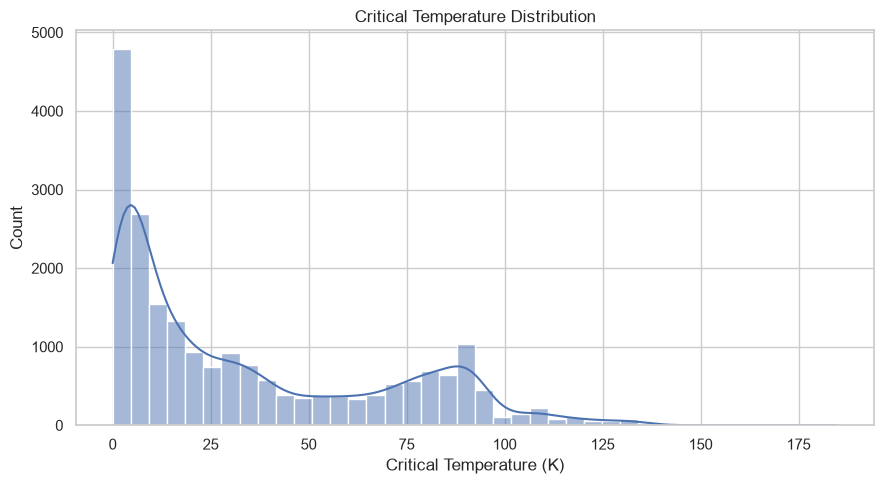

c:\Users\HP\AppData\Local\Programs\Python\Python311\Lib\site-packages\seaborn\categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)


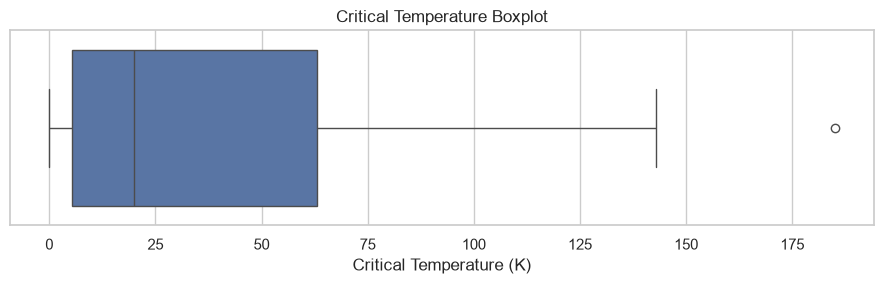


Top 10 features by absolute Pearson correlation:
wtd_std_ThermalConductivity    0.7213
range_ThermalConductivity      0.6877
range_atomic_radius            0.6538
std_ThermalConductivity        0.6536
wtd_mean_Valence              -0.6324
wtd_entropy_atomic_mass        0.6269
wtd_gmean_Valence             -0.6157
wtd_entropy_atomic_radius      0.6035
number_of_elements             0.6011
range_fie                      0.6008
Name: critical_temp, dtype: float64


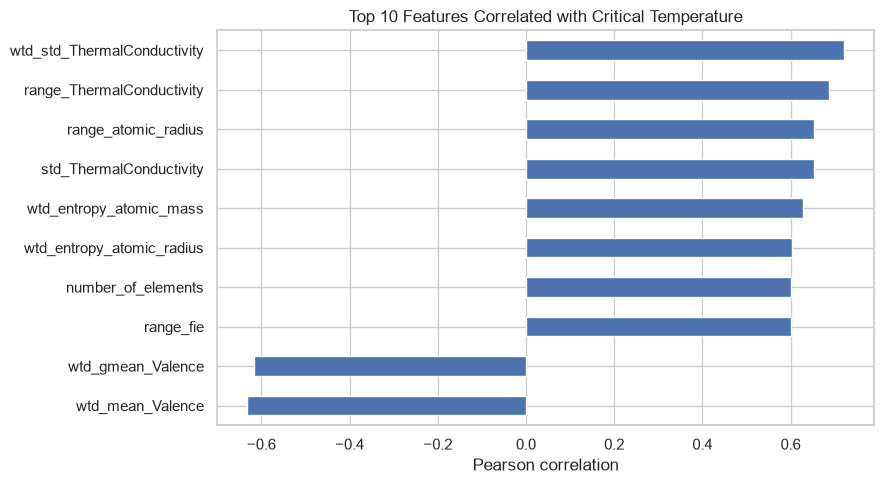


4. FEATURE PREPARATION
Number of samples: 21263
Number of features: 81
Unique feature-vector groups: 15170
Repeated feature-vector rows: 6093
Feature-vector groups with conflicting targets: 2374

5. GROUP-AWARE DATA SPLIT
Training: 14880 rows (69.98%)
Validation: 3227 rows (15.18%)
Testing: 3156 rows (14.84%)
Identical feature vectors cross splits: NO

6. EXTRA TREES REGRESSION
Model: ExtraTreesRegressor
Trees: 200

7. TRAINING VS VALIDATION


,Dataset,MAE,RMSE,R2
0,Training,1.3613,4.1653,0.9854
1,Validation,5.3867,10.0809,0.9093


Validation - training RMSE: 5.9156
Investigate possible overfitting and data differences.

8. FINAL PERFORMANCE


,Dataset,MAE,RMSE,R2
0,Training,1.3613,4.1653,0.9854
1,Validation,5.3867,10.0809,0.9093
2,Test,5.6441,10.3638,0.9086


Test MAE:  5.6441 K
Test RMSE: 10.3638 K
Test R2:   0.9086


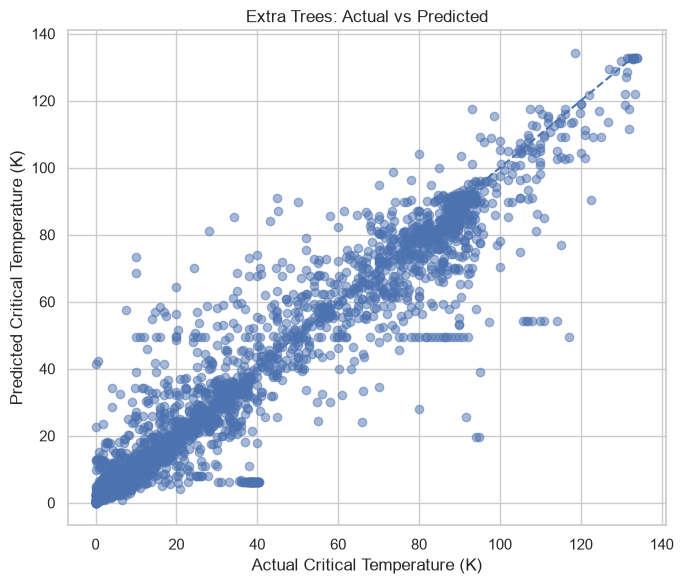

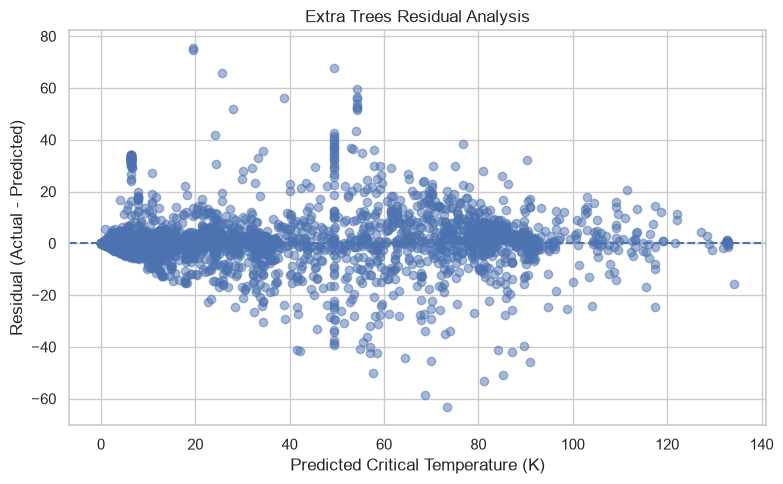


Top 15 features by Extra Trees importance:
range_ThermalConductivity          0.2046
wtd_std_ThermalConductivity        0.1670
std_ThermalConductivity            0.0584
range_atomic_radius                0.0469
wtd_mean_Valence                   0.0307
wtd_entropy_Valence                0.0291
wtd_entropy_atomic_mass            0.0268
wtd_gmean_Valence                  0.0228
wtd_gmean_ElectronAffinity         0.0219
range_fie                          0.0205
std_atomic_mass                    0.0169
wtd_entropy_atomic_radius          0.0152
wtd_std_ElectronAffinity           0.0128
wtd_entropy_ThermalConductivity    0.0128
wtd_std_Valence                    0.0128
dtype: float64


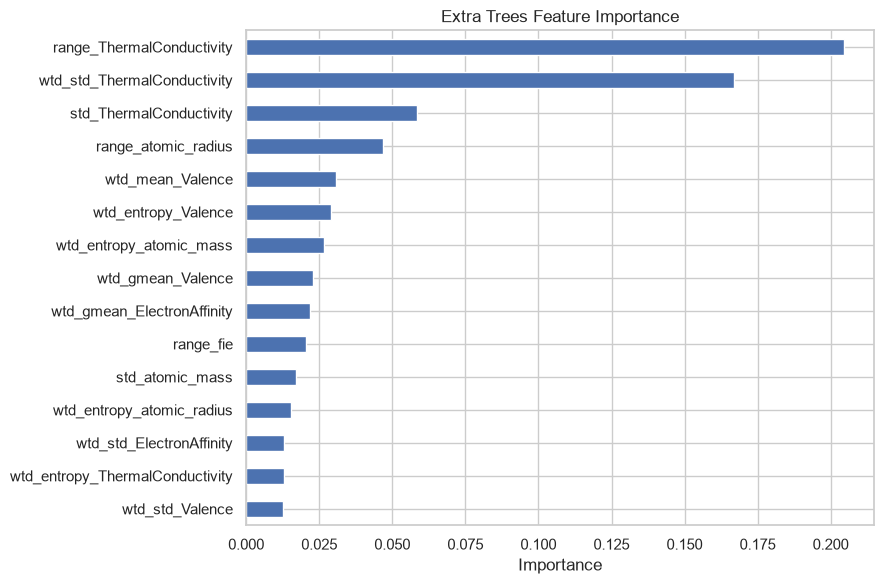


PIPELINE COMPLETED
Model used: ExtraTreesRegressor
Saved:
- outputs/extra_trees_evaluation.csv
- outputs/extra_trees_feature_importance.csv
- outputs/extra_trees_test_predictions.csv
- outputs/extra_trees_model.joblib


In [58]:

# ================================================================
# SUPERCONDUCTIVITY CRITICAL TEMPERATURE REGRESSION
# EDA + DATA VALIDATION + GROUP-AWARE SPLIT + EXTRA TREES
# VALIDATION + FINAL TESTING + DIAGNOSTICS + SAVED RESULTS
# ================================================================

import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import GroupShuffleSplit
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("default")
sns.set_theme(style="whitegrid")

TARGET = "critical_temp"
RANDOM_STATE = 42
OUTPUT_DIR = "outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# ================================================================
# 1. LOAD DATA
# ================================================================

train_df = pd.read_csv("data/train.csv")
formula_df = pd.read_csv("data/unique_m.csv")

print("=" * 70)
print("1. DATASET OVERVIEW")
print("=" * 70)
print("Training dataset:", train_df.shape)
print("Formula dataset:", formula_df.shape)
print("Target:", TARGET)

if TARGET not in train_df.columns:
    raise ValueError(f"Target column '{TARGET}' is missing.")

# ================================================================
# 2. DATA VALIDATION
# ================================================================

print("\n" + "=" * 70)
print("2. DATA VALIDATION")
print("=" * 70)

missing_values = int(train_df.isna().sum().sum())
duplicate_rows = int(train_df.duplicated().sum())

numeric_df = train_df.select_dtypes(include=np.number)
infinite_values = int(np.isinf(numeric_df.to_numpy()).sum())

print("Missing values:", missing_values)
print("Infinite numerical values:", infinite_values)
print("Exact duplicate rows:", duplicate_rows)
print("Missing target values:", train_df[TARGET].isna().sum())

# Check whether the two supplied files correspond row by row.
if len(train_df) != len(formula_df):
    raise ValueError("The two files have different row counts.")

if TARGET not in formula_df.columns:
    raise ValueError(f"Target column '{TARGET}' missing from formula_df.")

if not np.allclose(
    train_df[TARGET].to_numpy(),
    formula_df[TARGET].to_numpy(),
    equal_nan=True
):
    raise ValueError(
        "Target values do not align between the two files. "
        "Investigate before proceeding."
    )

print("Target alignment between files: PASS")

if missing_values > 0:
    raise ValueError(
        "Missing values detected. Investigate and document a "
        "handling strategy before training."
    )

if infinite_values > 0:
    raise ValueError(
        "Infinite numerical values detected. Investigate before training."
    )

if not np.isfinite(train_df[TARGET].to_numpy()).all():
    raise ValueError("The target contains non-finite values.")

# ================================================================
# 3. EXPLORATORY DATA ANALYSIS
# ================================================================

print("\n" + "=" * 70)
print("3. EXPLORATORY DATA ANALYSIS")
print("=" * 70)

print("\nData types:")
print(train_df.dtypes.value_counts())

print("\nTarget statistics:")
print(train_df[TARGET].describe().round(4))
print("Target skewness:", round(train_df[TARGET].skew(), 4))

# Target distribution
plt.figure(figsize=(9, 5))
sns.histplot(train_df[TARGET], bins=40, kde=True)
plt.title("Critical Temperature Distribution")
plt.xlabel("Critical Temperature (K)")
plt.tight_layout()
plt.show()

# Target boxplot
plt.figure(figsize=(9, 3))
sns.boxplot(x=train_df[TARGET])
plt.title("Critical Temperature Boxplot")
plt.xlabel("Critical Temperature (K)")
plt.tight_layout()
plt.show()

# Correlation analysis
correlations = (
    train_df.corr(numeric_only=True)[TARGET]
    .drop(TARGET)
    .sort_values(key=abs, ascending=False)
)

print("\nTop 10 features by absolute Pearson correlation:")
print(correlations.head(10).round(4))

plt.figure(figsize=(9, 5))
correlations.head(10).sort_values().plot(kind="barh")
plt.title("Top 10 Features Correlated with Critical Temperature")
plt.xlabel("Pearson correlation")
plt.tight_layout()
plt.show()

# ================================================================
# 4. PREPARE FEATURES AND TARGET
# ================================================================

print("\n" + "=" * 70)
print("4. FEATURE PREPARATION")
print("=" * 70)

X = train_df.drop(columns=[TARGET]).copy()
y = train_df[TARGET].copy()

if X.select_dtypes(exclude=np.number).shape[1] > 0:
    raise ValueError("Non-numeric predictor columns require preprocessing.")

if not np.isfinite(X.to_numpy()).all():
    raise ValueError("Non-finite predictor values detected.")

# Group identical engineered feature vectors together.
# This prevents exact duplicate X rows from crossing data splits.
groups = pd.util.hash_pandas_object(X, index=False).to_numpy()

print("Number of samples:", len(X))
print("Number of features:", X.shape[1])
print("Unique feature-vector groups:", pd.Series(groups).nunique())
print("Repeated feature-vector rows:", X.duplicated().sum())

# Audit conflicting targets for identical feature vectors.
audit = pd.DataFrame({
    "group": groups,
    "target": y.to_numpy()
})

group_target_counts = audit.groupby("group")["target"].nunique()
conflicting_groups = int((group_target_counts > 1).sum())

print("Feature-vector groups with conflicting targets:",
      conflicting_groups)

# Do not automatically delete or average these observations.
# Keep each identical feature vector in a single split.

# ================================================================
# 5. GROUP-AWARE TRAIN / VALIDATION / TEST SPLIT
# Approximate 70% training, 15% validation, 15% test.
# Group sizes can make exact percentages impossible.
# ================================================================

split1 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.15,
    random_state=RANDOM_STATE
)

train_val_idx, test_idx = next(
    split1.split(X, y, groups=groups)
)

X_train_val = X.iloc[train_val_idx]
y_train_val = y.iloc[train_val_idx]
groups_train_val = groups[train_val_idx]

split2 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.1764705882,
    random_state=RANDOM_STATE
)

train_idx, val_idx = next(
    split2.split(
        X_train_val,
        y_train_val,
        groups=groups_train_val
    )
)

X_train = X_train_val.iloc[train_idx]
y_train = y_train_val.iloc[train_idx]

X_val = X_train_val.iloc[val_idx]
y_val = y_train_val.iloc[val_idx]

X_test = X.iloc[test_idx]
y_test = y.iloc[test_idx]

# Verify no group crosses splits.
train_groups = set(groups[X_train.index.to_numpy()])
val_groups = set(groups[X_val.index.to_numpy()])
test_groups = set(groups[X_test.index.to_numpy()])

assert train_groups.isdisjoint(val_groups)
assert train_groups.isdisjoint(test_groups)
assert val_groups.isdisjoint(test_groups)

print("\n" + "=" * 70)
print("5. GROUP-AWARE DATA SPLIT")
print("=" * 70)

for name, part in [
    ("Training", X_train),
    ("Validation", X_val),
    ("Testing", X_test)
]:
    print(f"{name}: {len(part)} rows ({len(part)/len(X):.2%})")

print("Identical feature vectors cross splits: NO")

# ================================================================
# 6. TRAIN EXTRA TREES REGRESSOR
# ================================================================

print("\n" + "=" * 70)
print("6. EXTRA TREES REGRESSION")
print("=" * 70)

model = ExtraTreesRegressor(
    n_estimators=200,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

model.fit(X_train, y_train)

print("Model:", type(model).__name__)
print("Trees:", model.n_estimators)

# ================================================================
# 7. TRAINING AND VALIDATION EVALUATION
# ================================================================

def evaluate_regression(actual, predicted):
    return {
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "R2": r2_score(actual, predicted)
    }

train_pred = model.predict(X_train)
val_pred = model.predict(X_val)

train_metrics = evaluate_regression(y_train, train_pred)
val_metrics = evaluate_regression(y_val, val_pred)

evaluation = pd.DataFrame([
    {"Dataset": "Training", **train_metrics},
    {"Dataset": "Validation", **val_metrics}
])

print("\n" + "=" * 70)
print("7. TRAINING VS VALIDATION")
print("=" * 70)
display(evaluation.round(4))

rmse_gap = val_metrics["RMSE"] - train_metrics["RMSE"]

print("Validation - training RMSE:", round(rmse_gap, 4))

if val_metrics["RMSE"] > train_metrics["RMSE"] * 1.20:
    print("Warning: validation RMSE is substantially higher.")
    print("Investigate possible overfitting and data differences.")
else:
    print("No large RMSE gap detected by this rough diagnostic.")

# This heuristic is not a definitive overfitting test.

# ================================================================
# 8. FINAL TEST EVALUATION
# Test data has not been used for fitting or model selection.
# ================================================================

test_pred = model.predict(X_test)
test_metrics = evaluate_regression(y_test, test_pred)

final_results = pd.DataFrame([
    {"Dataset": "Training", **train_metrics},
    {"Dataset": "Validation", **val_metrics},
    {"Dataset": "Test", **test_metrics}
])

print("\n" + "=" * 70)
print("8. FINAL PERFORMANCE")
print("=" * 70)
display(final_results.round(4))

print(f"Test MAE:  {test_metrics['MAE']:.4f} K")
print(f"Test RMSE: {test_metrics['RMSE']:.4f} K")
print(f"Test R2:   {test_metrics['R2']:.4f}")

# ================================================================
# 9. ACTUAL VS PREDICTED
# ================================================================

plt.figure(figsize=(7, 6))
plt.scatter(y_test, test_pred, alpha=0.5)

lower = min(y_test.min(), test_pred.min())
upper = max(y_test.max(), test_pred.max())

plt.plot([lower, upper], [lower, upper], "--")
plt.xlabel("Actual Critical Temperature (K)")
plt.ylabel("Predicted Critical Temperature (K)")
plt.title("Extra Trees: Actual vs Predicted")
plt.tight_layout()
plt.show()

# ================================================================
# 10. RESIDUAL ANALYSIS
# ================================================================

residuals = y_test.to_numpy() - test_pred

plt.figure(figsize=(8, 5))
plt.scatter(test_pred, residuals, alpha=0.5)
plt.axhline(0, linestyle="--")
plt.xlabel("Predicted Critical Temperature (K)")
plt.ylabel("Residual (Actual - Predicted)")
plt.title("Extra Trees Residual Analysis")
plt.tight_layout()
plt.show()

# ================================================================
# 11. FEATURE IMPORTANCE
# ================================================================

importance = pd.Series(
    model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

print("\nTop 15 features by Extra Trees importance:")
print(importance.head(15).round(4))

plt.figure(figsize=(9, 6))
importance.head(15).sort_values().plot(kind="barh")
plt.title("Extra Trees Feature Importance")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

# ================================================================
# 12. SAVE RESULTS
# ================================================================

final_results.to_csv(
    f"{OUTPUT_DIR}/extra_trees_evaluation.csv",
    index=False
)

importance.rename("importance").to_csv(
    f"{OUTPUT_DIR}/extra_trees_feature_importance.csv"
)

pd.DataFrame({
    "Actual": y_test.to_numpy(),
    "Predicted": test_pred,
    "Residual": residuals
}).to_csv(
    f"{OUTPUT_DIR}/extra_trees_test_predictions.csv",
    index=False
)

joblib.dump(
    model,
    f"{OUTPUT_DIR}/extra_trees_model.joblib"
)

print("\n" + "=" * 70)
print("PIPELINE COMPLETED")
print("=" * 70)
print("Model used: ExtraTreesRegressor")
print("Saved:")
print("- outputs/extra_trees_evaluation.csv")
print("- outputs/extra_trees_feature_importance.csv")
print("- outputs/extra_trees_test_predictions.csv")
print("- outputs/extra_trees_model.joblib")


In [59]:

print("MODEL:", type(model).__name__)

print("\nDATA SPLIT SIZES")
print("Train:", len(X_train))
print("Validation:", len(X_val))
print("Test:", len(X_test))

print("\nFEATURE GROUP OVERLAP")

train_groups_check = set(
    pd.util.hash_pandas_object(X_train, index=False)
)
val_groups_check = set(
    pd.util.hash_pandas_object(X_val, index=False)
)
test_groups_check = set(
    pd.util.hash_pandas_object(X_test, index=False)
)

print("Train-validation overlap:",
      len(train_groups_check & val_groups_check))

print("Train-test overlap:",
      len(train_groups_check & test_groups_check))

print("Validation-test overlap:",
      len(val_groups_check & test_groups_check))


MODEL: ExtraTreesRegressor

DATA SPLIT SIZES
Train: 14880
Validation: 3227
Test: 3156

FEATURE GROUP OVERLAP
Train-validation overlap: 0
Train-test overlap: 0
Validation-test overlap: 0


In [60]:

print("TRAINING METRICS")
print("MAE:", mean_absolute_error(y_train, model.predict(X_train)))
print("RMSE:", np.sqrt(mean_squared_error(y_train, model.predict(X_train))))
print("R2:", r2_score(y_train, model.predict(X_train)))

print("\nVALIDATION METRICS")
print("MAE:", mean_absolute_error(y_val, model.predict(X_val)))
print("RMSE:", np.sqrt(mean_squared_error(y_val, model.predict(X_val))))
print("R2:", r2_score(y_val, model.predict(X_val)))

print("\nTEST METRICS")
print("MAE:", mean_absolute_error(y_test, model.predict(X_test)))
print("RMSE:", np.sqrt(mean_squared_error(y_test, model.predict(X_test))))
print("R2:", r2_score(y_test, model.predict(X_test)))


TRAINING METRICS
MAE: 1.3612955667850113
RMSE: 4.165310988972671
R2: 0.9853507517072927

VALIDATION METRICS
MAE: 5.386656143407885
RMSE: 10.08094314496922
R2: 0.9093086590359679

TEST METRICS
MAE: 5.644062093039785
RMSE: 10.363845205963075
R2: 0.9085535915090353


In [61]:

from sklearn.ensemble import ExtraTreesRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Test several Extra Trees configurations
configurations = [
    {
        "name": "Baseline",
        "n_estimators": 200,
        "max_depth": None,
        "min_samples_leaf": 1,
        "max_features": 1.0
    },
    {
        "name": "Moderate Regularization",
        "n_estimators": 300,
        "max_depth": 30,
        "min_samples_leaf": 2,
        "max_features": 1.0
    },
    {
        "name": "Stronger Regularization",
        "n_estimators": 300,
        "max_depth": 20,
        "min_samples_leaf": 3,
        "max_features": 1.0
    },
    {
        "name": "Feature Subsampling",
        "n_estimators": 300,
        "max_depth": 30,
        "min_samples_leaf": 2,
        "max_features": 0.8
    }
]

comparison = []
candidates = {}

for cfg in configurations:
    name = cfg["name"]

    model_candidate = ExtraTreesRegressor(
        n_estimators=cfg["n_estimators"],
        max_depth=cfg["max_depth"],
        min_samples_leaf=cfg["min_samples_leaf"],
        max_features=cfg["max_features"],
        random_state=42,
        n_jobs=-1
    )

    model_candidate.fit(X_train, y_train)

    train_pred = model_candidate.predict(X_train)
    val_pred = model_candidate.predict(X_val)

    train_rmse = np.sqrt(
        mean_squared_error(y_train, train_pred)
    )
    val_rmse = np.sqrt(
        mean_squared_error(y_val, val_pred)
    )

    comparison.append({
        "Configuration": name,
        "Train RMSE": train_rmse,
        "Validation MAE": mean_absolute_error(y_val, val_pred),
        "Validation RMSE": val_rmse,
        "Validation R2": r2_score(y_val, val_pred),
        "RMSE Gap": val_rmse - train_rmse
    })

    candidates[name] = model_candidate

comparison_df = (
    pd.DataFrame(comparison)
    .sort_values("Validation RMSE")
    .reset_index(drop=True)
)

display(comparison_df.round(4))

# Select using validation RMSE only
best_name = comparison_df.loc[0, "Configuration"]
best_candidate = candidates[best_name]

print("Best configuration:", best_name)
print("Selection criterion: lowest validation RMSE")


,Configuration,Train RMSE,Validation MAE,Validation RMSE,Validation R2,RMSE Gap
0,Baseline,4.1653,5.3867,10.0809,0.9093,5.9156
1,Moderate Regularization,4.6962,5.4695,10.0814,0.9093,5.3852
2,Stronger Regularization,5.5478,5.6310,10.0998,0.9090,4.5520
3,Feature Subsampling,4.7409,5.4972,10.1178,0.9086,5.3769


Best configuration: Baseline
Selection criterion: lowest validation RMSE


In [62]:

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Final selected model
final_model = candidates["Baseline"]

# Evaluate once on the held-out test set
test_pred = final_model.predict(X_test)

final_test_results = pd.DataFrame([{
    "Model": "Extra Trees Regressor (Baseline)",
    "Test MAE (K)": mean_absolute_error(y_test, test_pred),
    "Test RMSE (K)": np.sqrt(
        mean_squared_error(y_test, test_pred)
    ),
    "Test R2": r2_score(y_test, test_pred)
}])

display(final_test_results.round(4))

final_test_results.to_csv(
    "outputs/extra_trees_final_test_results.csv",
    index=False
)

print("Final test results saved.")


,Model,Test MAE (K),Test RMSE (K),Test R2
0,Extra Trees Regressor (Baseline),5.6441,10.3638,0.9086


Final test results saved.


In [63]:
import joblib

joblib.dump(
    final_model,
    "outputs/extra_trees_model.joblib"
)

print("Trained Extra Trees model saved successfully.")

Trained Extra Trees model saved successfully.
